# Oficina de Machine Learning | Regressão: quanto um estudante tira de nota?

**Projeto:** Tempo de jogo e desempenho acadêmico
**Base:** `Base_Original_GrupoGamingvsAcademicPerformance.csv` (8.000 estudantes, 14 variáveis)
**Alvo:** `grades`, a nota do estudante (0 a 100)

Este notebook é a adaptação do notebook-oficina de regressão à base do projeto do grupo. Ele dá continuidade ao
`Analise_GrupoGamingvsAcademicPerformance.ipynb` (AV1), que fez a preparação e a análise exploratória da mesma base:
as regras de limpeza da função `limpar` (seção 1.3) são exatamente as decisões tomadas lá, e as variáveis criadas na
seção 4.1 vêm das "próximas etapas" apontadas na conclusão daquele notebook.

## Roteiro
| Seção | Etapa | Pergunta | Etapa da aula 11 |
|---|---|---|---|
| 0 | Configuração e carregamento | De onde vêm os dados e o que se quer prever? | 1. Problema |
| 1 | Auditoria inicial da base | Há problemas de tipo, ausência, duplicata ou consistência? | 2. Dados |
| 2 | Divisão treino e teste | Como separar os dados antes de tomar decisões? | 5. Treino e teste |
| 3 | EDA inicial (no treino) | O que os dados mostram sobre o alvo? | 3. Variáveis |
| 4 | Pré-processamento | O que precisa ser transformado, e por quê? | 4. Preparação |
| 5 | EDA de validação | O pré-processamento fez o que deveria? Há vazamento? | 4. Preparação |
| 6 | Modelagem | Qual modelo e qual complexidade generalizam melhor? | 6. Treinamento |
| 7 | Avaliação final no teste | Qual o desempenho em dados nunca vistos? | 7. Previsões e 8. Avaliação |
| 8 | Análise de erros e interpretação | Onde o modelo erra e o que ele aprendeu? | 9. Interpretação |
| 9 | Conclusões | | |
| 10 | Desafios | | |
| 11 | Entrega: o que foi adaptado | | |

Sequência correta vista em aula: (1) limpar o que é regra fixa, (2) separar treino e teste, (3) ajustar as transformações só no treino, (4) escolher o modelo sem olhar o teste, (5) usar o teste uma única vez.

## Como este notebook se liga ao trabalho do grupo

| Etapa do projeto | Onde está |
|---|---|
| Preparação dos dados e EDA descritiva | `Analise_GrupoGamingvsAcademicPerformance.ipynb` (AV1) |
| **Previsão da nota (regressão)** | **este notebook** |
| Previsão do risco de baixo desempenho (classificação) | `oficina_ML_Classificacao_GrupoGamingvsAcademicPerformance.ipynb` |

A AV1 terminou com quatro perguntas em aberto. Duas delas são respondidas aqui:

1. *"Existe um ponto de virada nas horas de jogo?"* → a variável `faixa_jogo` (seção 4.1) separa jogo leve, moderado e excessivo.
2. *"Qual o peso relativo de cada fator na nota?"* → os coeficientes da regressão linear e as importâncias da árvore (seção 8.1).

Partimos da **base original**, e não da pré-processada, porque a oficina pede que as regras de limpeza fiquem explícitas
dentro da função `limpar` — ela é reaplicada a qualquer dado novo que o modelo venha a receber.

# 0. Configuração e carregamento

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

## Parâmetros do problema

In [2]:
ALVO = 'grades'                # nota do estudante, de 0 a 100: a variável que se quer prever
COLUNAS_FORA = ['student_id']  # identificador: não descreve o estudante, só o numera
PROPORCAO_TESTE = 0.25         # parte da base guardada para a avaliação final
NOTA_MAXIMA = 100              # teto da escala de notas, usado na limpeza
SEED = 42

In [3]:
# A base do projeto é um arquivo local. O notebook procura o CSV nos caminhos abaixo.
# No Google Colab, envie o arquivo (ícone de pasta, à esquerda) ou descomente as três linhas finais.

CAMINHOS = ['dados/Base_Original_GrupoGamingvsAcademicPerformance.csv',
            'Base_Original_GrupoGamingvsAcademicPerformance.csv',
            '../dados/Base_Original_GrupoGamingvsAcademicPerformance.csv']
ARQUIVO_LOCAL = next((c for c in CAMINHOS if os.path.exists(c)), None)

# from google.colab import files
# enviados = files.upload()
# ARQUIVO_LOCAL = list(enviados.keys())[0]

if ARQUIVO_LOCAL is None:   # último recurso: baixar a base direto do Kaggle, como na AV1
    import glob, kagglehub
    ARQUIVO_LOCAL = glob.glob(os.path.join(kagglehub.dataset_download('aiexplorer77/gaming-vs-academic-performance'), '*.csv'))[0]
print('Arquivo:', ARQUIVO_LOCAL)

Arquivo: dados/Base_Original_GrupoGamingvsAcademicPerformance.csv


In [4]:
df_bruto = pd.read_csv(ARQUIVO_LOCAL, sep=None, engine='python')
print('Shape:', df_bruto.shape)
df_bruto.head()

Shape: (8000, 14)


,student_id,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades
0,1,22,Male,7.230,8.780,6.960,91.440,FPS,3.250,9.360,235.840,14.690,Low,86.460
1,2,19,Male,0.070,8.720,7.630,63.630,Casual,1.020,3.210,328.710,2.470,Medium,98.230
2,3,23,Female,1.730,9.560,4.400,83.260,Casual,3.460,5.560,313.610,4.730,High,90.560
3,4,20,Female,6.620,1.680,7.830,75.040,RPG,1.460,11.780,241.840,14.540,Low,32.670
4,5,22,Female,5.360,5.830,5.550,65.570,FPS,1.010,8.230,249.310,12.480,Low,58.710


# 1. Auditoria inicial da base

In [5]:
df_bruto.info()
pd.DataFrame({'dtype': df_bruto.dtypes.astype(str), 'distintos': df_bruto.nunique(),
              'exemplo': [df_bruto[c].dropna().iloc[0] for c in df_bruto.columns]})

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        8000 non-null   int64  
 1   age               8000 non-null   int64  
 2   gender            8000 non-null   str    
 3   gaming_hours      8000 non-null   float64
 4   study_hours       8000 non-null   float64
 5   sleep_hours       8000 non-null   float64
 6   attendance        8000 non-null   float64
 7   gaming_genre      8000 non-null   str    
 8   social_activity   8000 non-null   float64
 9   device_usage      8000 non-null   float64
 10  reaction_time_ms  8000 non-null   float64
 11  addiction_score   8000 non-null   float64
 12  stress_level      8000 non-null   str    
 13  grades            8000 non-null   float64
dtypes: float64(9), int64(2), str(3)
memory usage: 875.1 KB


,dtype,distintos,exemplo
student_id,int64,8000,1
age,int64,9,22
gender,str,3,Male
gaming_hours,float64,801,7.230
study_hours,float64,901,8.780
sleep_hours,float64,501,6.960
attendance,float64,3472,91.440
gaming_genre,str,3,FPS
social_activity,float64,501,3.250
device_usage,float64,1202,9.360


**Leitura.** As 14 colunas chegam com o tipo certo: onze numéricas (`student_id`, `age`, `gaming_hours`, `study_hours`,
`sleep_hours`, `attendance`, `social_activity`, `device_usage`, `reaction_time_ms`, `addiction_score` e o alvo `grades`)
e três de texto (`gender`, `gaming_genre`, `stress_level`). `student_id` tem 8.000 valores distintos, um por linha:
é identificador, não variável, e por isso entra em `COLUNAS_FORA`. As três categóricas têm três categorias cada,
sem variações de grafia. Nenhuma conversão de tipo é necessária, o que é diferente da base de exemplo da oficina.

## 1.2 Qualidade dos dados

In [6]:
# Completude: NaN e ausentes "disfarçados" (texto vazio, '?', 'NA'...), que o pandas não reconhece.
disfarcados = ['', ' ', '?', 'na', 'n/a', 'nan', 'none', 'null', '-']
tab_ausentes = pd.DataFrame({
    'NaN': df_bruto.isnull().sum(),
    '% NaN': (100 * df_bruto.isnull().mean()).round(2),
    'disfarçados': [df_bruto[c].astype(str).str.strip().str.lower().isin(disfarcados).sum()
                    if not pd.api.types.is_numeric_dtype(df_bruto[c]) else 0 for c in df_bruto.columns],
})
display(tab_ausentes)
print('Linhas duplicadas (iguais em todas as colunas):', df_bruto.duplicated().sum())
print('student_id repetidos:', df_bruto['student_id'].duplicated().sum())

,NaN,% NaN,disfarçados
student_id,0,0.000,0
age,0,0.000,0
gender,0,0.000,0
gaming_hours,0,0.000,0
study_hours,0,0.000,0
sleep_hours,0,0.000,0
attendance,0,0.000,0
gaming_genre,0,0.000,0
social_activity,0,0.000,0
device_usage,0,0.000,0


Linhas duplicadas (iguais em todas as colunas): 0
student_id repetidos: 0


In [7]:
texto = df_bruto.select_dtypes(exclude='number').drop(columns=COLUNAS_FORA + [ALVO], errors='ignore')
for c in texto.columns:
    print(f'{c:<14}', sorted(texto[c].astype(str).unique()))

# Faixas de validade das colunas desta base (regras do domínio, definidas na AV1).
soma_horas = df_bruto['gaming_hours'] + df_bruto['study_hours'] + df_bruto['sleep_hours']
regras = {
    'grades entre 0 e 100': ~df_bruto['grades'].between(0, NOTA_MAXIMA),
    'attendance entre 0 e 100': ~df_bruto['attendance'].between(0, 100),
    'addiction_score >= 0': ~(df_bruto['addiction_score'] >= 0),
    'age entre 10 e 100': ~df_bruto['age'].between(10, 100),
    'jogo + estudo + sono <= 24h por dia': soma_horas > 24,
}
display(pd.DataFrame({'violações': {k: int(v.sum()) for k, v in regras.items()},
                      '% da base': {k: round(100 * v.mean(), 2) for k, v in regras.items()}}))

gender         ['Female', 'Male', 'Other']
gaming_genre   ['Casual', 'FPS', 'RPG']
stress_level   ['High', 'Low', 'Medium']


,violações,% da base
grades entre 0 e 100,134,1.680
attendance entre 0 e 100,0,0.000
addiction_score >= 0,107,1.340
age entre 10 e 100,0,0.000
jogo + estudo + sono <= 24h por dia,98,1.230


**Leitura.** Não há ausentes (nem NaN nem disfarçados), não há linhas duplicadas e `student_id` não se repete:
cada linha é um estudante. As categorias são consistentes (`Female`/`Male`/`Other`, `Casual`/`FPS`/`RPG`,
`Low`/`Medium`/`High`), sem espaços ou grafias diferentes.

O problema desta base está nas **faixas de validade**, e são os mesmos três casos identificados na AV1:

| Inconsistência | Linhas | % da base | Por que é impossível |
|---|---|---|---|
| `grades` acima de 100 | 134 | 1,68% | a escala de notas vai até 100 |
| `addiction_score` negativo | 107 | 1,34% | um escore de dependência não pode ser menor que zero |
| jogo + estudo + sono acima de 24h | 98 | 1,23% | o dia tem 24 horas |

Cada caso afeta menos de 2% da base. Nenhum é erro de digitação isolado: são artefatos da **simulação** que gerou os
dados (a própria descrição do dataset informa que ele é sintético). O tratamento vai para a função `limpar`.

## 1.3 Limpeza determinística

In [8]:
def limpar(d):
    d = d.copy()
    # Regras gerais (servem para qualquer base): texto sem espaços nas pontas e vazio como ausente.
    for c in d.select_dtypes(exclude='number').columns:
        d[c] = d[c].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan})
    d = d.drop_duplicates()

    # Regras desta base (as mesmas decisões tomadas na AV1):
    d['grades'] = d['grades'].clip(0, NOTA_MAXIMA)             # 134 notas acima de 100 -> limitadas ao teto da escala
    d['addiction_score'] = d['addiction_score'].clip(lower=0)  # 107 escores negativos -> limitados a zero
    horas = d['gaming_hours'] + d['study_hours'] + d['sleep_hours']
    d = d[horas <= 24]                                         # 98 dias de mais de 24h -> removidos (não dá para saber qual hora está errada)
    d = d[d[ALVO].notna()]                                     # sem nota, a linha não serve para treinar nem para avaliar
    return d


df = limpar(df_bruto)
y = df[ALVO]
X = df.drop(columns=[ALVO] + COLUNAS_FORA)
print(f'Linhas: {len(df_bruto)} -> {len(df)} | features: {X.shape[1]}')
print('Ausentes depois da limpeza:', int(X.isnull().sum().sum()))

Linhas: 8000 -> 7902 | features: 12
Ausentes depois da limpeza: 0


**Por que limitar em vez de remover?** Nos dois primeiros casos sabemos qual é o valor correto mais próximo (o teto da
escala e o zero), e remover 241 estudantes jogaria fora as outras 12 informações de cada um. No terceiro caso não é
possível saber qual das três horas está errada, então limitar não resolveria: essas 98 linhas saem da base.
A base de trabalho fica com **7.902 estudantes**, a mesma quantidade da base pré-processada da AV1.

# 2. Divisão treino e teste

In [9]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=PROPORCAO_TESTE, random_state=SEED)
print(f'Treino: {len(X_treino)} linhas | Teste: {len(X_teste)} linhas')
pd.DataFrame({'treino': y_treino.describe(), 'teste': y_teste.describe()}).round(1)

Treino: 5926 linhas | Teste: 1976 linhas


,treino,teste
count,"5,926.000","1,976.000"
mean,66.000,65.500
std,22.200,22.600
min,0.000,7.200
25%,49.700,49.200
50%,66.700,66.500
75%,84.000,83.200
max,100.000,100.000


A divisão vem **antes** da EDA: tudo o que for decidido daqui para a frente (variáveis criadas, imputação, escolha de
modelo) olha só para o treino. O teste fica guardado e é usado uma única vez, na seção 7.

# 3. EDA inicial (no treino)

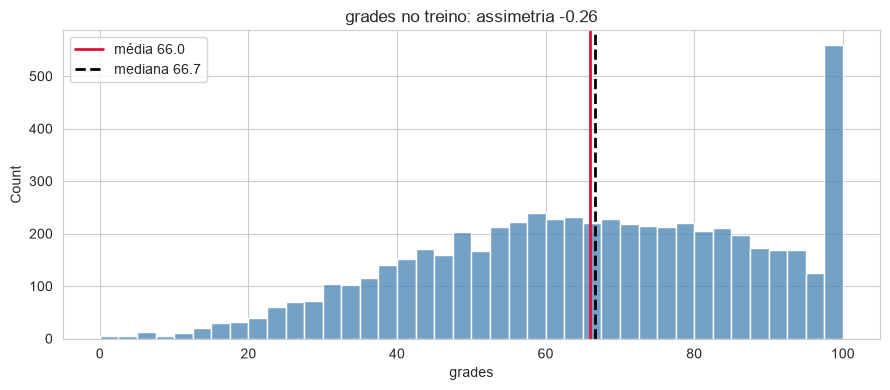

Referência: prever sempre a média do treino (66.0) erra em média 18.5 pontos (MAE no próprio treino).


In [10]:
eda = X_treino.assign(alvo=y_treino.values)
NUM = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
CAT = [c for c in X.columns if c not in NUM]
plt.figure(figsize=(9, 4))
sns.histplot(y_treino, bins=40, color='steelblue')
plt.axvline(y_treino.mean(), color='crimson', lw=2, label=f'média {y_treino.mean():,.1f}')
plt.axvline(y_treino.median(), color='black', ls='--', lw=2, label=f'mediana {y_treino.median():,.1f}')
plt.title(f'{ALVO} no treino: assimetria {y_treino.skew():.2f}')
plt.legend()
plt.tight_layout()
plt.show()
erro_ref = mean_absolute_error(y_treino, np.full(len(y_treino), y_treino.mean()))
print(f'Referência: prever sempre a média do treino ({y_treino.mean():,.1f}) erra em média {erro_ref:,.1f} pontos (MAE no próprio treino).')

**Leitura.** A nota é **quase simétrica** (assimetria −0,26), com média 66,0 e mediana 66,7, espalhada por quase toda a
escala. Não há a cauda longa à direita da base de exemplo da oficina, então **não faz sentido transformar o alvo**.
O acúmulo visível em 100 são os 134 estudantes cujas notas foram limitadas ao teto na seção 1.3.

A referência que o modelo precisa superar é simples: chutar sempre a média (66,0) erra **18,5 pontos** em média.
Como a nota vai de 0 a 100, errar 18,5 pontos é quase não saber nada — é a distância entre uma reprovação e uma boa nota.

## 3.2 Variáveis numéricas

,n,média,mediana,desvio padrão,mín,Q1,Q3,máx,IQR,assimetria,outliers (IQR),% outliers
age,"5,926.000",19.970,20.000,2.590,16.000,18.000,22.000,24.000,4.000,-0.000,0.000,0.000
gaming_hours,"5,926.000",4.040,4.090,2.290,0.000,2.110,5.980,8.000,3.870,-0.040,0.000,0.000
study_hours,"5,926.000",5.430,5.390,2.570,1.000,3.190,7.610,10.000,4.420,0.040,0.000,0.000
sleep_hours,"5,926.000",6.470,6.480,1.440,4.000,5.220,7.700,9.000,2.480,0.020,0.000,0.000
attendance,"5,926.000",79.830,79.640,11.530,60.000,69.750,89.960,100.000,20.210,0.030,0.000,0.000
social_activity,"5,926.000",2.500,2.500,1.440,0.000,1.260,3.760,5.000,2.500,-0.000,0.000,0.000
device_usage,"5,926.000",7.540,7.560,2.700,1.100,5.520,9.550,13.910,4.030,-0.010,0.000,0.000
reaction_time_ms,"5,926.000",271.690,271.130,29.070,183.260,248.260,295.080,343.490,46.820,0.030,0.000,0.000
addiction_score,"5,926.000",9.820,9.850,4.970,0.000,5.880,13.700,23.010,7.820,0.020,0.000,0.000


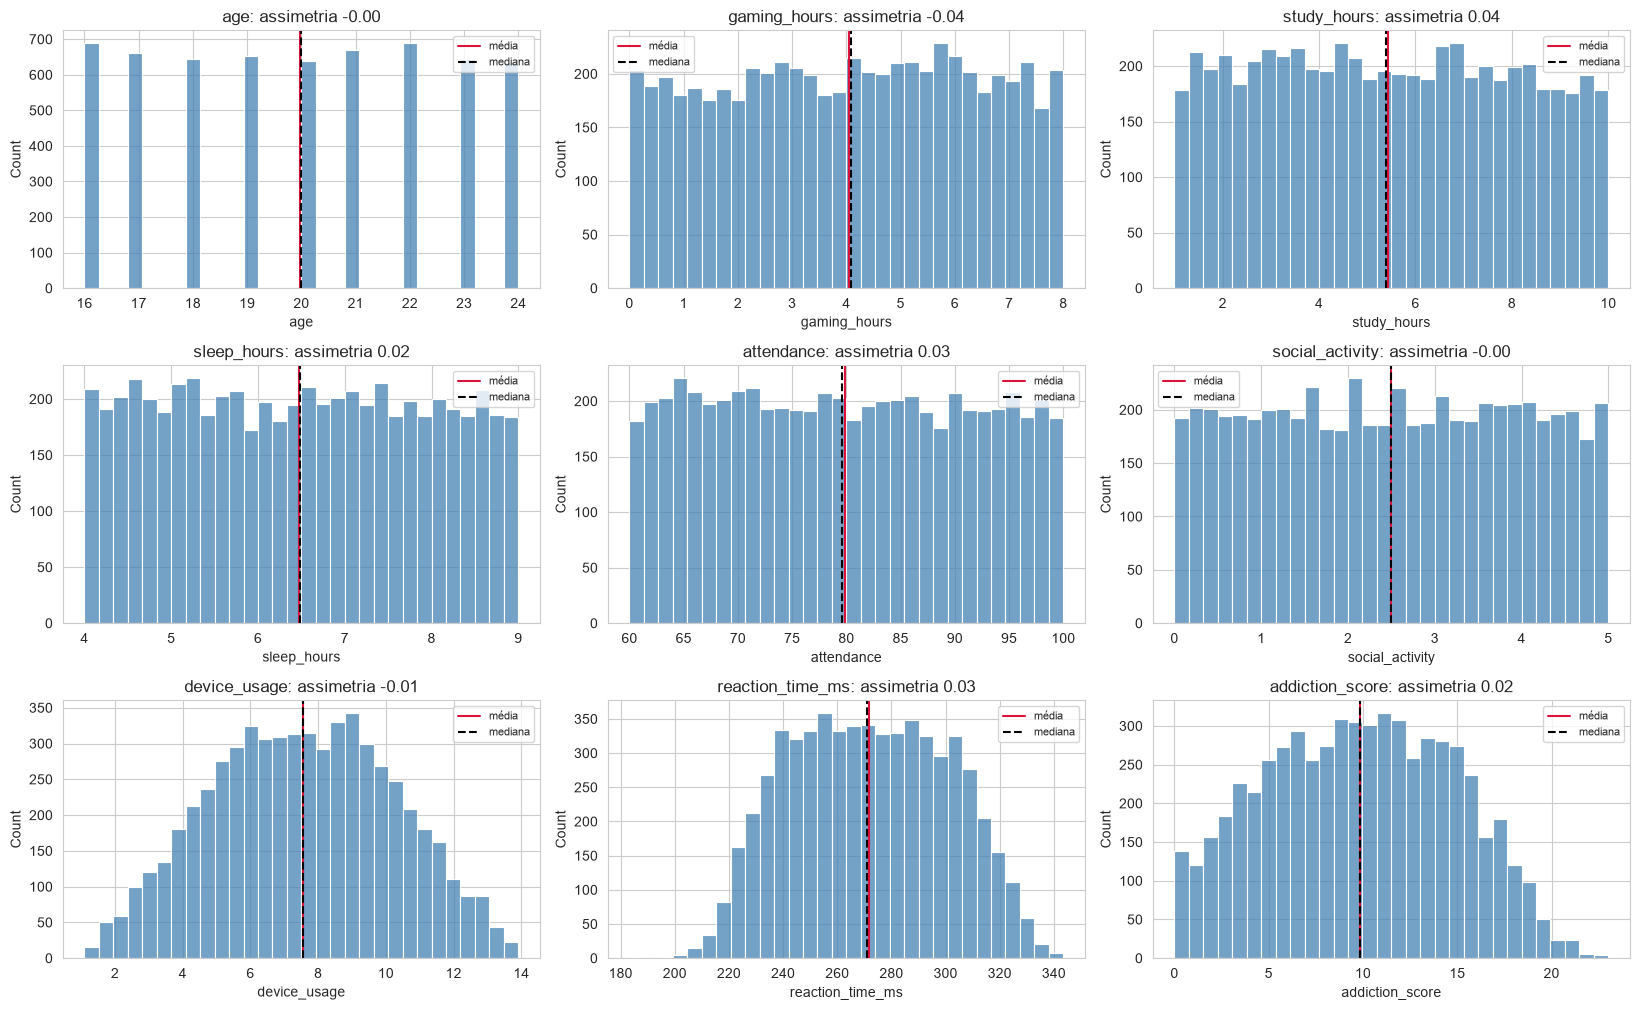

In [11]:
def resumo_numerico(dados):
    # Centro, dispersão, forma e extremos (medidas vistas na aula de EDA).
    linhas = {}
    for c in dados.columns:
        x = dados[c].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
        linhas[c] = {'n': len(x), 'média': x.mean(), 'mediana': x.median(), 'desvio padrão': x.std(),
                     'mín': x.min(), 'Q1': q1, 'Q3': q3, 'máx': x.max(), 'IQR': iqr,
                     'assimetria': x.skew(), 'outliers (IQR)': n_out, '% outliers': 100 * n_out / len(x)}
    return pd.DataFrame(linhas).T


def outliers_iqr(x):
    # Regra do boxplot: fora de [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)


def outliers_desvio(x, k=3):
    # Regra do desvio padrão: mais de k desvios da média (z-score)
    return ((x - x.mean()) / x.std()).abs() > k


display(resumo_numerico(eda[NUM]).round(2))
colunas = 3
linhas = int(np.ceil(len(NUM) / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5.5 * colunas, 3.4 * linhas), squeeze=False)
for ax, c in zip(axes.flat, NUM):
    sns.histplot(eda[c].dropna(), bins=30, ax=ax, color='steelblue')
    ax.axvline(eda[c].mean(), color='crimson', lw=1.5, label='média')
    ax.axvline(eda[c].median(), color='black', ls='--', lw=1.5, label='mediana')
    ax.set_title(f'{c}: assimetria {eda[c].skew():.2f}')
    ax.legend(fontsize=8)
for ax in axes.flat[len(NUM):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Leitura.** Todas as nove numéricas têm assimetria praticamente zero (entre −0,04 e +0,04) e média igual à mediana.
Os histogramas mostram por quê: `gaming_hours` (0 a 8h), `study_hours` (1 a 10h), `sleep_hours` (4 a 9h),
`attendance` (60 a 100%), `social_activity` (0 a 5) e `age` (16 a 24) são **uniformes**, com cortes exatos nos extremos.

Isso é uma assinatura de dados simulados, e não de uma turma real — em uma turma real, horas de estudo e frequência
seriam assimétricas. `device_usage`, `reaction_time_ms` e `addiction_score` têm forma de sino, sinal de que foram
geradas a partir das outras. Para a modelagem, a consequência prática é boa: nenhuma variável precisa de transformação
de escala ou de log.

## 3.3 Variáveis categóricas

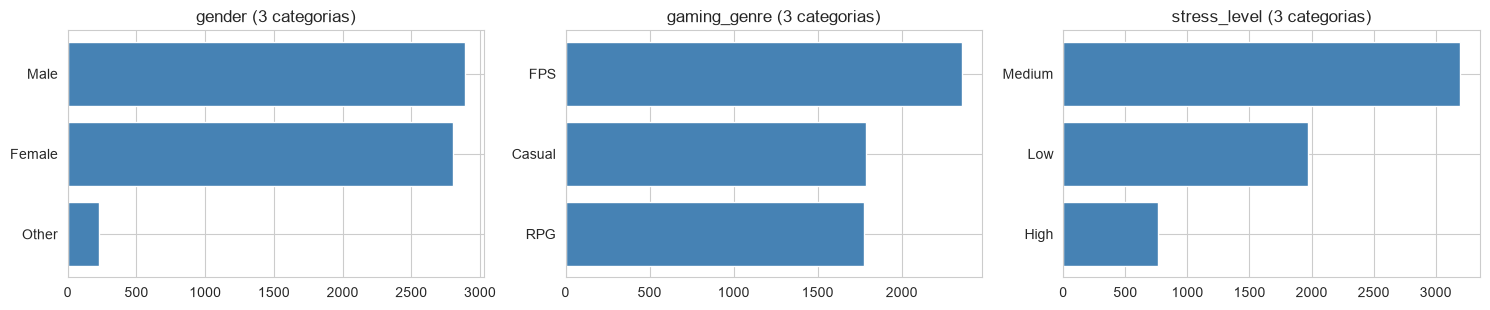

,proporção no treino
gender,
Male,0.487
Female,0.474
Other,0.039


,proporção no treino
gaming_genre,
FPS,0.398
Casual,0.302
RPG,0.300


,proporção no treino
stress_level,
Medium,0.539
Low,0.332
High,0.128


In [12]:
fig, axes = plt.subplots(1, len(CAT), figsize=(5 * len(CAT), 3.2), squeeze=False)
for ax, c in zip(axes[0], CAT):
    freq = eda[c].value_counts().head(10)
    ax.barh(freq.index.astype(str)[::-1], freq.values[::-1], color='steelblue')
    ax.set_title(f'{c} ({eda[c].nunique()} categorias)')
plt.tight_layout()
plt.show()
for c in CAT:
    display(eda[c].value_counts(normalize=True).round(3).to_frame('proporção no treino'))

**Leitura.** `gender` e `gaming_genre` são equilibradas (`Male` 48,7% e `Female` 47,4%, com `Other` em 3,9%;
os três gêneros de jogo ficam entre 30% e 40%). `stress_level` é a única desbalanceada: `Medium` concentra 54%,
`Low` 33% e `High` apenas 13%. Nenhuma categoria tem menos de 30 observações, então todas podem ser usadas.
Não há categorias raras para agrupar.

## 3.4 Outliers: erro ou caso real?

In [13]:
display(pd.DataFrame({'outliers (IQR)': {c: int(outliers_iqr(eda[c].dropna()).sum()) for c in NUM + ['alvo']},
                      'outliers (|z| > 3)': {c: int(outliers_desvio(eda[c].dropna()).sum()) for c in NUM + ['alvo']}}))
fora = outliers_iqr(eda['alvo'])
print(f'Outliers do alvo pela regra do IQR: {int(fora.sum())} linhas.')
if fora.sum() > 0:
    perfil = {f'média de {c}': (eda.loc[fora, c].mean(), eda.loc[~fora, c].mean()) for c in NUM}
    for c in CAT:
        for v in sorted(eda[c].dropna().unique()):
            perfil[f'% {c} = {v}'] = (100 * (eda.loc[fora, c] == v).mean(), 100 * (eda.loc[~fora, c] == v).mean())
    display(pd.DataFrame(perfil, index=['outliers do alvo', 'demais']).T.round(1))
else:
    print('Nada a investigar: as duas regras não encontram valores extremos no alvo.')

,outliers (IQR),outliers (|z| > 3)
age,0,0
gaming_hours,0,0
study_hours,0,0
sleep_hours,0,0
attendance,0,0
social_activity,0,0
device_usage,0,0
reaction_time_ms,0,1
addiction_score,0,0
alvo,0,0


Outliers do alvo pela regra do IQR: 0 linhas.
Nada a investigar: as duas regras não encontram valores extremos no alvo.


**Leitura.** Depois da limpeza da seção 1.3, **nenhuma variável tem outlier pela regra do IQR** e apenas
`reaction_time_ms` tem um valor além de 3 desvios da média. Esse resultado é consequência direta de duas coisas:
as distribuições uniformes (que não produzem caudas) e o tratamento já feito nos valores impossíveis.

Diferente da base de exemplo da oficina — onde os 96 outliers do custo eram fumantes, um grupo real que o modelo
precisava aprender —, aqui não há nenhum subgrupo extremo a investigar. **Nada mais precisa ser removido.**

## 3.5 Numéricas e o alvo

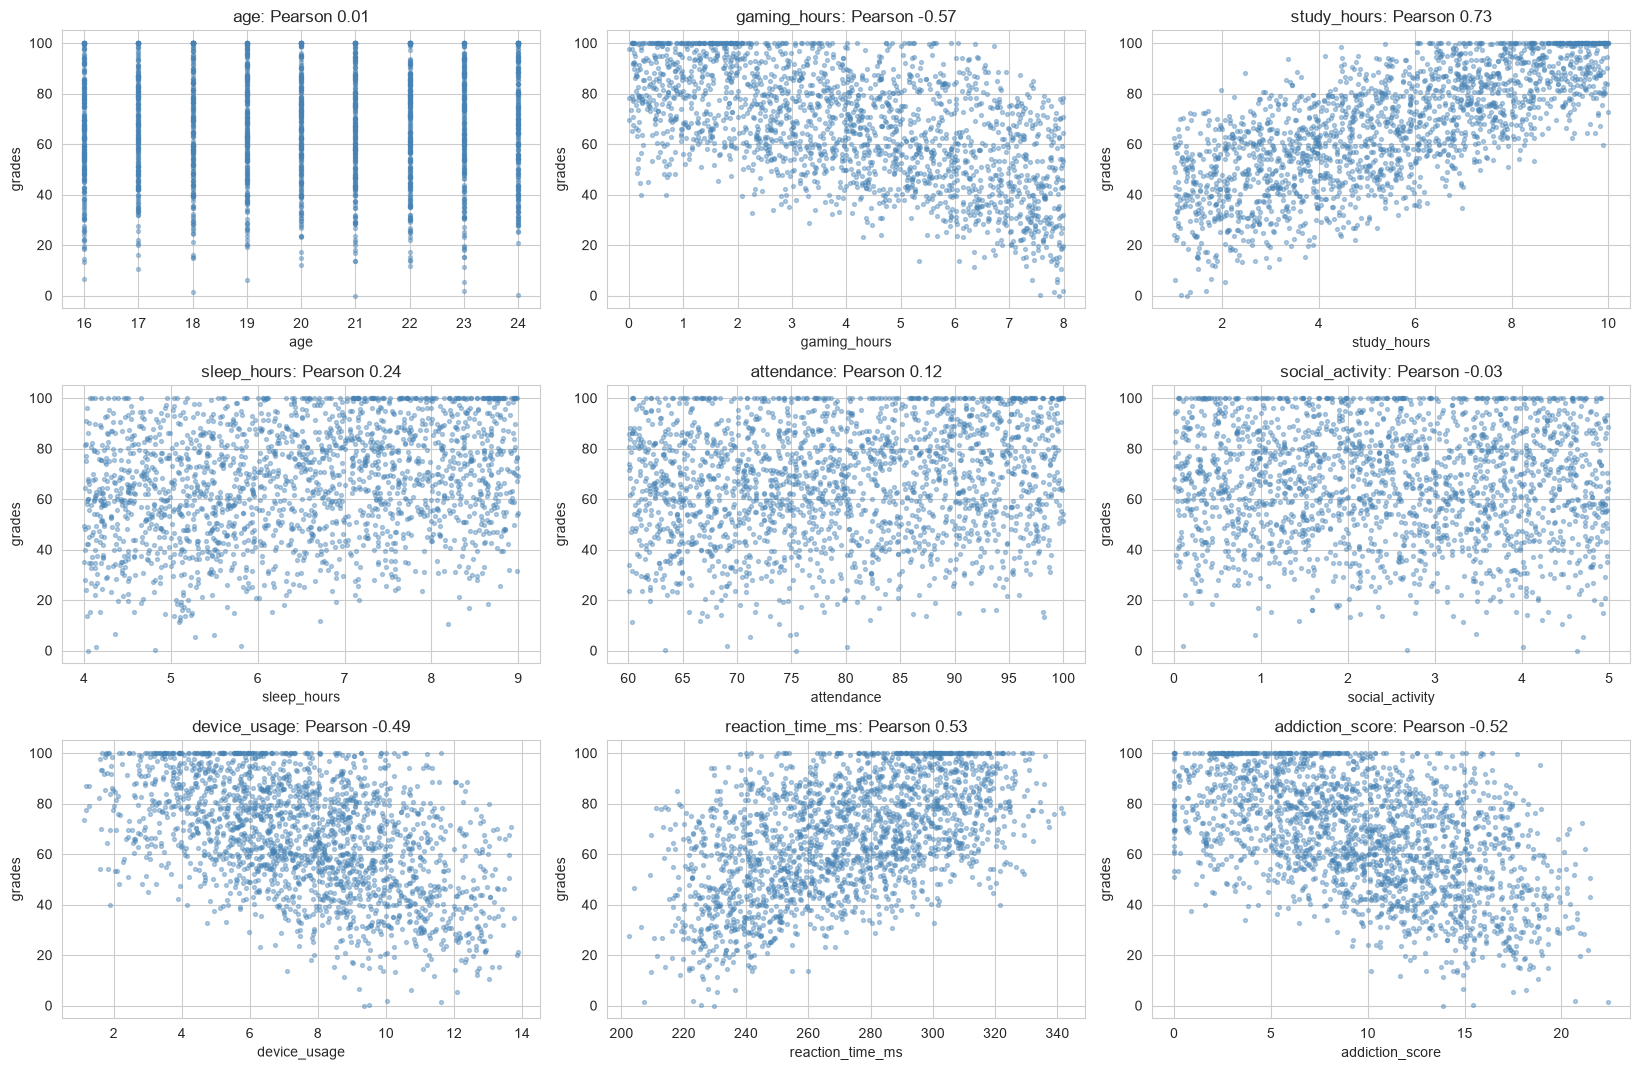

,Pearson com a nota
study_hours,0.731
gaming_hours,-0.569
reaction_time_ms,0.534
addiction_score,-0.515
device_usage,-0.488
sleep_hours,0.244
attendance,0.124
social_activity,-0.026
age,0.006


In [14]:
colunas = 3
linhas = int(np.ceil(len(NUM) / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5.5 * colunas, 3.6 * linhas), squeeze=False)
amostra = eda.sample(min(2000, len(eda)), random_state=SEED)
for ax, c in zip(axes.flat, NUM):
    ax.scatter(amostra[c], amostra['alvo'], s=8, alpha=0.4, color='steelblue')
    ax.set(xlabel=c, ylabel=ALVO, title=f'{c}: Pearson {eda[c].corr(eda["alvo"]):.2f}')
for ax in axes.flat[len(NUM):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
eda[NUM].corrwith(eda['alvo']).sort_values(key=abs, ascending=False).round(3).to_frame('Pearson com a nota')

**Leitura.** O ranking confirma, agora só no treino, o que a AV1 encontrou na base inteira:

| Variável | Pearson com a nota | Leitura |
|---|---|---|
| `study_hours` | **+0,731** | a mais associada à nota, e de longe |
| `gaming_hours` | **−0,569** | quanto mais jogo, menor a nota |
| `reaction_time_ms` | +0,534 | tempo de reação maior acompanha nota maior |
| `addiction_score` | −0,515 | escore de dependência alto acompanha nota baixa |
| `device_usage` | −0,488 | mesmo sentido do tempo de jogo |
| `sleep_hours` | +0,244 | associação fraca e positiva |
| `attendance` | +0,124 | quase irrelevante |
| `social_activity` | −0,026 | sem associação |
| `age` | +0,006 | sem associação |

Os gráficos de dispersão mostram nuvens largas com tendência linear clara em `study_hours` e `gaming_hours`: não há
curva nem patamar, o que já indica que uma **regressão linear tem chance de ir bem**. `attendance`, `social_activity`
e `age` produzem nuvens sem inclinação — provavelmente não entrarão no modelo final com peso relevante.

O caso de `reaction_time_ms` merece atenção: um tempo de reação **maior** acompanhando nota **maior** é contraintuitivo.
A explicação aparece na seção 3.7.

## 3.6 Categóricas e o alvo: média por categoria

,amplitude da média (pontos)
stress_level,31.150
gender,1.790
gaming_genre,1.170


,n,media,mediana
stress_level,,,
Low,1968,49.630,46.980
Medium,3197,72.550,72.100
High,761,80.790,82.050


,n,media,mediana
gender,,,
Other,231,64.670,65.560
Male,2888,65.660,66.260
Female,2807,66.460,67.230


,n,media,mediana
gaming_genre,,,
RPG,1775,65.410,66.390
FPS,2361,66.000,66.580
Casual,1790,66.580,67.280


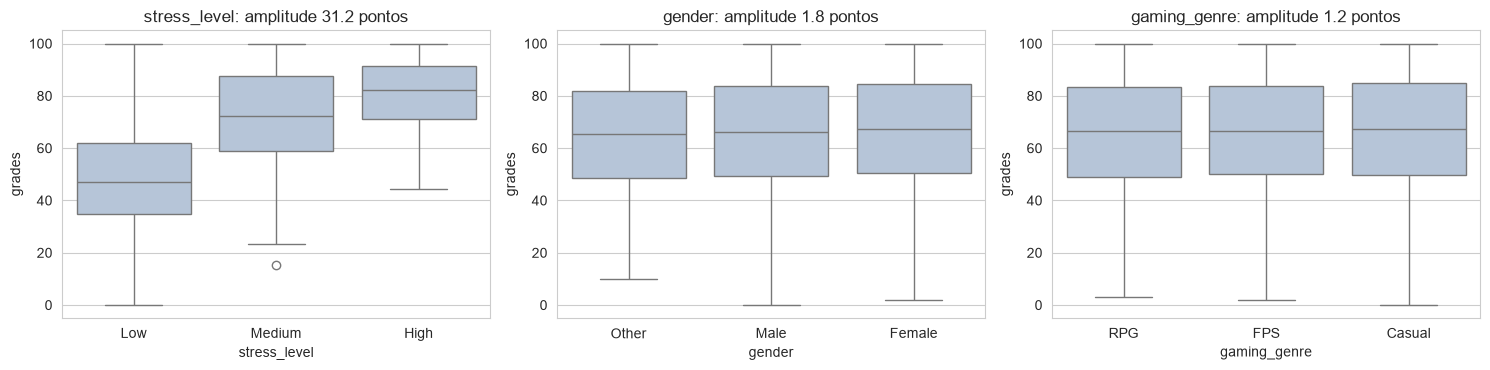

In [15]:
def media_por(col):
    return eda.groupby(col, observed=True)['alvo'].agg(n='count', media='mean', mediana='median').sort_values('media')


amplitude = pd.Series({c: media_por(c).query('n >= 30')['media'].agg(lambda s: s.max() - s.min()) for c in CAT}).sort_values(ascending=False)
display(amplitude.round(2).to_frame('amplitude da média (pontos)'))
for c in amplitude.index:
    display(media_por(c).round(2))
fig, axes = plt.subplots(1, len(CAT), figsize=(5 * len(CAT), 3.8), squeeze=False)
for ax, c in zip(axes[0], amplitude.index):
    sns.boxplot(data=eda, x=c, y='alvo', ax=ax, color='lightsteelblue', order=media_por(c).index)
    ax.set(title=f'{c}: amplitude {amplitude[c]:,.1f} pontos', ylabel=ALVO)
plt.tight_layout()
plt.show()

**Leitura.** Só uma das três categóricas separa a nota: `stress_level`, com **31,2 pontos** de amplitude.
E o sentido é o oposto do esperado:

| `stress_level` | n | nota média |
|---|---|---|
| Low | 1.968 | **49,6** |
| Medium | 3.197 | 72,6 |
| High | 761 | **80,8** |

Quem declara estresse **alto** tira, em média, 31 pontos a mais do que quem declara estresse baixo. A AV1 já havia
marcado esse resultado como contraintuitivo e pendente de investigação. A explicação mais provável aparece na seção 3.7:
estresse alto anda junto com muitas horas de estudo — o estresse não causa a nota, ele é um **marcador de quem estuda muito**.

`gender` (1,8 ponto) e `gaming_genre` (1,2 ponto) são praticamente irrelevantes: a diferença entre jogar RPG (65,4) e
Casual (66,6) é menor que o erro de qualquer modelo. Isso também replica o achado da AV1 de que o gênero de jogo não
tem relação com a nota — **o que importa é quanto se joga, não o que se joga**.

## 3.7 Relações entre variáveis e discretização

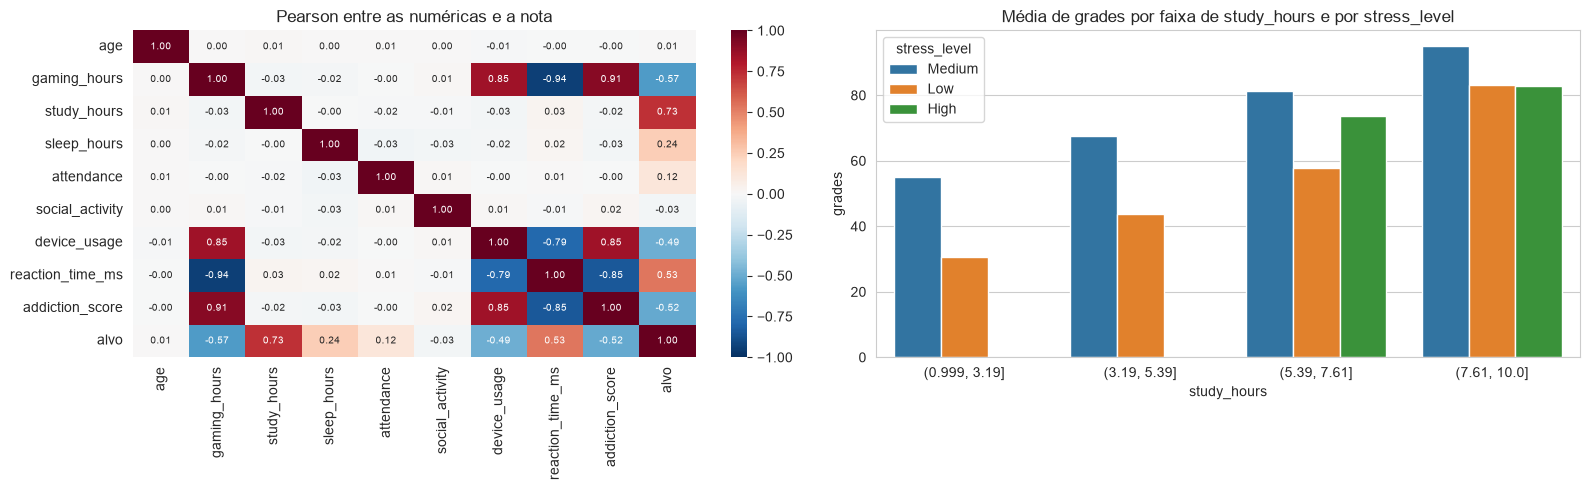

Correlação de gaming_hours com as demais numéricas:


,Pearson
reaction_time_ms,-0.940
addiction_score,0.910
device_usage,0.850
study_hours,-0.030
sleep_hours,-0.020
social_activity,0.010
age,0.000
attendance,-0.000


Distribuição de stress_level por faixa de study_hours (% da linha):


stress_level,High,Low,Medium
study_hours,,,
"(0.999, 3.19]",0.000,38.400,61.600
"(3.19, 5.39]",0.000,41.200,58.800
"(5.39, 7.61]",12.100,32.100,55.800
"(7.61, 10.0]",39.400,21.100,39.500


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(eda[NUM + ['alvo']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=axes[0], annot_kws={'size': 7})
axes[0].set_title('Pearson entre as numéricas e a nota')
principal = eda[NUM].corrwith(eda['alvo']).abs().idxmax()
grupo = amplitude.index[0]
faixas = pd.qcut(eda[principal], 4, duplicates='drop')
sns.barplot(data=eda.assign(faixa=faixas.astype(str)).dropna(subset=[principal]), x='faixa', y='alvo', hue=grupo,
            ax=axes[1], errorbar=None, order=[str(c) for c in faixas.cat.categories])
axes[1].set(title=f'Média de {ALVO} por faixa de {principal} e por {grupo}', xlabel=principal, ylabel=ALVO)
plt.tight_layout()
plt.show()

print('Correlação de gaming_hours com as demais numéricas:')
display(eda[NUM].corr()['gaming_hours'].drop('gaming_hours').sort_values(key=abs, ascending=False).round(2).to_frame('Pearson'))
print('Distribuição de stress_level por faixa de study_hours (% da linha):')
display((100 * pd.crosstab(faixas, eda[grupo], normalize='index')).round(1))

**Leitura.** Dois achados importantes para a modelagem.

**1. Quatro variáveis medem a mesma coisa.** `gaming_hours` tem correlação **−0,94 com `reaction_time_ms`**,
**+0,91 com `addiction_score`** e **+0,85 com `device_usage`** (e `device_usage` × `addiction_score` = 0,85).
Não são quatro informações: é **uma só** — o quanto o estudante joga —, medida de quatro formas. Isso explica o
contrassenso do tempo de reação: ele não ajuda a nota, ele apenas é baixo em quem joga muito. É redundância
(multicolinearidade), não vazamento: todas são conhecidas antes da prova. Para a árvore isso é inofensivo; para a
regressão linear significa que os coeficientes dessas quatro variáveis **se dividem de forma instável** e não devem
ser lidos isoladamente.

**2. O estresse é um marcador de esforço.** A tabela cruzada mostra que, no quartil de menos estudo
(até 3,2h), não há praticamente nenhum estudante com estresse alto; no quartil de mais estudo (acima de 7,6h) a
categoria `High` aparece com força. Dentro de **cada** faixa de horas de estudo o estresse ainda separa as notas,
mas a maior parte dos 31 pontos de amplitude vem de quem estuda mais também declarar mais estresse. É a resposta à
pergunta deixada em aberto na AV1.

A redundância é quantificada abaixo pelo **fator de inflação da variância (VIF)**, a medida usual do problema em
regressão: ele mede o quanto cada variável é previsível a partir das demais, e valores acima de 5 indicam que a
variável não traz informação própria (O'Brien, 2007).

**Discretização:** o gráfico de barras mostra que a nota sobe de forma regular a cada quartil de horas de estudo
(31 → 44 → 58 → 83 entre os de estresse baixo), sem patamar nem salto. Então **não vale discretizar `study_hours`**:
a relação é linear e a variável contínua carrega mais informação. Já para `gaming_hours` as faixas são úteis por
outro motivo — responder à pergunta da AV1 sobre o "ponto de virada" (seção 4.1).

In [17]:
# VIF: 1 / (1 - R² da variável explicada por todas as outras numéricas). Acima de 5 indica redundância.
def vif(dados, coluna):
    outras = [c for c in dados.columns if c != coluna]
    X = np.column_stack([np.ones(len(dados))] + [dados[c].values for c in outras])
    beta, *_ = np.linalg.lstsq(X, dados[coluna].values, rcond=None)
    erro = dados[coluna].values - X @ beta
    r2 = 1 - (erro ** 2).sum() / ((dados[coluna].values - dados[coluna].mean()) ** 2).sum()
    return 1 / (1 - r2)

tab_vif = pd.Series({c: vif(eda[NUM], c) for c in NUM}).sort_values(ascending=False).to_frame('VIF')
tab_vif['diagnóstico'] = np.where(tab_vif['VIF'] >= 10, 'redundância alta',
                          np.where(tab_vif['VIF'] >= 5, 'redundância moderada', 'sem redundância'))
display(tab_vif.round(1))

,VIF,diagnóstico
gaming_hours,14.200,redundância alta
reaction_time_ms,8.300,redundância moderada
addiction_score,6.500,redundância moderada
device_usage,4.100,sem redundância
sleep_hours,1.000,sem redundância
social_activity,1.000,sem redundância
attendance,1.000,sem redundância
study_hours,1.000,sem redundância
age,1.000,sem redundância


**Leitura do VIF.** O diagnóstico é claro e localizado: `gaming_hours` (14,2), `reaction_time_ms` (8,3) e
`addiction_score` (6,5) ficam acima do limite de atenção, `device_usage` (4,1) logo abaixo dele, e **todas as outras
cinco numéricas ficam em VIF ≈ 1,0**. Não é um problema difuso de multicolinearidade: é **um bloco de quatro colunas
que medem o mesmo comportamento**.

A consequência prática é que colocar as quatro juntas em uma regressão linear faz o coeficiente de cada uma depender
das outras três, de forma instável — nenhum deles pode ser lido como "o efeito do tempo de jogo". Mantemos as quatro
no modelo (a árvore é indiferente a isso e o objetivo principal é prever, não explicar), mas a seção **6.6** compara
o modelo com e sem o bloco redundante antes de qualquer interpretação dos coeficientes.

## 3.8 Síntese: achados e decisões

| # | Achado na EDA do treino | Decisão |
|---|---|---|
| 1 | A nota é quase simétrica (assimetria −0,26), média 66,0 | Não transformar o alvo; usar MAE em pontos da nota |
| 2 | Referência (prever sempre a média) erra 18,5 pontos | Qualquer modelo tem de ficar bem abaixo disso |
| 3 | `study_hours` é a variável mais associada à nota (r = +0,731) | Entra como contínua, sem discretizar |
| 4 | `gaming_hours` é a segunda (r = −0,569) | Entra contínua **e** em faixas, para testar o ponto de virada |
| 5 | `reaction_time_ms`, `addiction_score` e `device_usage` são redundantes com `gaming_hours` (\|r\| de 0,85 a 0,94) | Mantidas (não atrapalham a árvore), mas seus coeficientes não serão interpretados isoladamente |
| 6 | `stress_level` separa 31,2 pontos, mas é marcador de horas de estudo | Mantida como feature; **não** será lida como causa |
| 7 | `gender` (1,8 pt), `gaming_genre` (1,2 pt), `age`, `social_activity` e `attendance` quase não separam | Mantidas; espera-se peso próximo de zero |
| 8 | Sem ausentes, sem duplicatas e sem outliers após a limpeza | Imputação fica no pipeline só por segurança, para dados novos |
| 9 | As distribuições uniformes indicam base simulada | Entra como limitação na conclusão (seção 9) |

# 4. Pré-processamento

In [18]:
def criar_atributos(X):
    X = X.copy()
    # 1. Faixas de jogo: responde à pergunta da AV1 sobre o "ponto de virada" (leve / moderado / excessivo).
    X['faixa_jogo'] = pd.cut(X['gaming_hours'], bins=[-0.01, 2, 5, 24],
                             labels=['leve (até 2h)', 'moderado (2h a 5h)', 'excessivo (+5h)']).astype(str)
    # 2. Saldo entre estudo e jogo: combina as duas variáveis mais associadas à nota em uma só.
    X['saldo_estudo_jogo'] = (X['study_hours'] - X['gaming_hours']).round(2)
    # 3. Combinação de dois riscos, no espírito do 'fumante_obeso' da oficina.
    X['jogo_alto_estudo_baixo'] = np.where((X['gaming_hours'] > 5) & (X['study_hours'] < 4), 'sim', 'não')
    # 4. Sono abaixo do recomendado para a faixa etária.
    X['sono_insuficiente'] = np.where(X['sleep_hours'] < 6, 'sim', 'não')
    return X


X_treino = criar_atributos(X_treino)
X_teste = criar_atributos(X_teste)
NUM = [c for c in X_treino.columns if pd.api.types.is_numeric_dtype(X_treino[c])]
CAT = [c for c in X_treino.columns if c not in NUM]
print('Numéricas:', NUM)
print('Categóricas:', CAT)

novas = X_treino.assign(alvo=y_treino.values)
for c in ['faixa_jogo', 'jogo_alto_estudo_baixo', 'sono_insuficiente']:
    display(novas.groupby(c, observed=True)['alvo'].agg(n='count', nota_media='mean').round(2))

Numéricas: ['age', 'gaming_hours', 'study_hours', 'sleep_hours', 'attendance', 'social_activity', 'device_usage', 'reaction_time_ms', 'addiction_score', 'saldo_estudo_jogo']
Categóricas: ['gender', 'gaming_genre', 'stress_level', 'faixa_jogo', 'jogo_alto_estudo_baixo', 'sono_insuficiente']


,n,nota_media
faixa_jogo,,
excessivo (+5h),2262,52.440
leve (até 2h),1427,82.060
moderado (2h a 5h),2237,69.460


,n,nota_media
jogo_alto_estudo_baixo,,
não,5135,71.010
sim,791,33.450


,n,nota_media
sono_insuficiente,,
não,3518,69.950
sim,2408,60.230


**Leitura das variáveis criadas.** Todas são calculadas a partir de colunas conhecidas **antes** da prova, então
nenhuma introduz vazamento. As quatro foram escolhidas a partir da EDA:

| Variável criada | O que mostra no treino |
|---|---|
| `faixa_jogo` | leve (até 2h): **82,1** · moderado: **69,5** · excessivo (+5h): **52,4** |
| `saldo_estudo_jogo` | `study_hours − gaming_hours`: junta em um número as duas variáveis mais fortes |
| `jogo_alto_estudo_baixo` | sim (791 estudantes): nota média **33,5** · não (5.135): **71,0** |
| `sono_insuficiente` | sim (2.408): **60,2** · não (3.518): **70,0** |

A resposta à pergunta da AV1 sobre o ponto de virada: a queda é **constante, não abrupta** — cada faixa perde cerca de
12 a 17 pontos para a anterior, sem um limiar em que a nota despenca. O que realmente marca um grupo crítico é a
**combinação**: os 791 estudantes que jogam mais de 5h e estudam menos de 4h tiram, em média, 33,5 pontos —
37 pontos abaixo dos demais. É o análogo do `fumante_obeso` da oficina.

## 4.2 Pipeline de preparação

In [19]:
def criar_preparo():
    return ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), NUM),
        ('categoricas', Pipeline([('ausente', SimpleImputer(strategy='constant', fill_value='ausente')),
                                  ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT)],
        verbose_feature_names_out=False)


def transformar(prep, dados):
    return pd.DataFrame(prep.transform(dados), columns=prep.get_feature_names_out(), index=dados.index)


preparo = criar_preparo().fit(X_treino)
Xtr_p, Xte_p = transformar(preparo, X_treino), transformar(preparo, X_teste)
print(f'{X_treino.shape[1]} colunas originais -> {Xtr_p.shape[1]} colunas depois do one-hot')
Xtr_p.head()

16 colunas originais -> 20 colunas depois do one-hot


,age,gaming_hours,study_hours,sleep_hours,attendance,social_activity,device_usage,reaction_time_ms,addiction_score,saldo_estudo_jogo,gender_Male,gender_Other,gaming_genre_FPS,gaming_genre_RPG,stress_level_Low,stress_level_Medium,faixa_jogo_leve (até 2h),faixa_jogo_moderado (2h a 5h),jogo_alto_estudo_baixo_sim,sono_insuficiente_sim
7535,23.000,1.770,4.880,8.230,73.340,2.490,4.090,290.140,2.970,3.110,0.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000
6543,24.000,0.700,1.590,8.820,87.580,0.430,4.200,298.890,1.700,0.890,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000
6893,23.000,3.790,7.300,7.820,65.940,3.040,8.990,280.610,9.390,3.510,0.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000
949,21.000,1.020,7.750,6.300,91.150,0.540,4.930,317.300,0.740,6.730,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000
1973,18.000,6.240,7.800,6.660,84.860,1.490,8.630,249.270,14.660,1.560,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000


O pipeline faz três coisas: imputa numéricas pela **mediana do treino**, imputa categóricas com a marca `'ausente'` e
aplica one-hot nas categóricas. Ele é **ajustado só no treino** (`.fit(X_treino)`) e depois apenas aplicado ao teste —
é isso que impede o vazamento de informação do teste para a preparação. As 16 colunas viram 20 depois do one-hot.

# 5. EDA de validação

In [20]:
checks = {
    'sem ausentes depois da preparação': int(Xtr_p.isnull().sum().sum() + Xte_p.isnull().sum().sum()) == 0,
    'treino e teste com as mesmas colunas': list(Xtr_p.columns) == list(Xte_p.columns),
    'treino e teste sem linhas em comum': len(set(X_treino.index) & set(X_teste.index)) == 0,
    'alvo e colunas excluídas fora das features': not any(c in X_treino.columns for c in [ALVO] + COLUNAS_FORA),
    'one-hot: no máximo uma coluna ativa por variável': all(Xtr_p[[k for k in Xtr_p.columns if k.startswith(c + '_')]].sum(axis=1).max() <= 1 for c in CAT),
}
pd.DataFrame({'resultado': {k: 'OK' if v else 'FALHOU' for k, v in checks.items()}})

,resultado
sem ausentes depois da preparação,OK
treino e teste com as mesmas colunas,OK
treino e teste sem linhas em comum,OK
alvo e colunas excluídas fora das features,OK
one-hot: no máximo uma coluna ativa por variável,OK


## 5.2 Treino e teste continuam comparáveis?

In [21]:
display(pd.DataFrame({'média treino': X_treino[NUM].mean(), 'média teste': X_teste[NUM].mean(),
                      'mediana treino': X_treino[NUM].median(), 'mediana teste': X_teste[NUM].median()}).round(2))
print(f'Alvo: média treino {y_treino.mean():,.1f} | média teste {y_teste.mean():,.1f}')
c = amplitude.index[0]
pd.DataFrame({'treino': X_treino[c].value_counts(normalize=True), 'teste': X_teste[c].value_counts(normalize=True)}).round(3)

,média treino,média teste,mediana treino,mediana teste
age,19.970,20.020,20.000,20.000
gaming_hours,4.040,4.070,4.090,4.110
study_hours,5.430,5.370,5.390,5.430
sleep_hours,6.470,6.470,6.480,6.460
attendance,79.830,80.040,79.640,79.850
social_activity,2.500,2.530,2.500,2.500
device_usage,7.540,7.550,7.560,7.560
reaction_time_ms,271.690,271.240,271.130,271.130
addiction_score,9.820,9.920,9.850,10.000
saldo_estudo_jogo,1.390,1.310,1.310,1.240


Alvo: média treino 66.0 | média teste 65.5


,treino,teste
stress_level,,
Medium,0.539,0.531
Low,0.332,0.343
High,0.128,0.126


**Leitura.** Treino e teste são comparáveis: as médias das nove numéricas batem na primeira casa decimal, a nota média
fica em 66,0 no treino e 65,5 no teste (meio ponto de diferença, dentro do esperado para uma divisão aleatória) e a
distribuição de `stress_level` é praticamente idêntica nos dois. Não há deslocamento entre os conjuntos que possa
explicar, depois, uma diferença de desempenho.

## 5.3 Verificação de vazamento

In [22]:
def erro_uma_feature(Xa, ya, Xb, yb, coluna):
    cols_num = [coluna] if pd.api.types.is_numeric_dtype(Xa[coluna]) else []
    prep = ColumnTransformer([('n', SimpleImputer(strategy='median'), cols_num),
                              ('c', Pipeline([('a', SimpleImputer(strategy='constant', fill_value='ausente')),
                                              ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), [coluna] if not cols_num else [])])
    m = Pipeline([('p', prep), ('m', DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED))]).fit(Xa[[coluna]], ya)
    return mean_absolute_error(yb, m.predict(Xb[[coluna]]))


# treino dividido em duas partes para não usar o teste
Xa, Xb, ya, yb = train_test_split(X_treino, y_treino, test_size=0.3, random_state=SEED)

# Coluna fictícia, só para demonstrar como um vazamento se denuncia: a nota da prova final
# só é conhecida DEPOIS do fim do semestre, ou seja, depois do momento em que a previsão seria usada.
rng = np.random.default_rng(SEED)
Xa_demo = Xa.assign(nota_prova_final=(0.95 * ya * rng.uniform(0.97, 1.03, len(ya))).round(1))
Xb_demo = Xb.assign(nota_prova_final=(0.95 * yb * rng.uniform(0.97, 1.03, len(yb))).round(1))

referencia = mean_absolute_error(yb, np.full(len(yb), ya.mean()))
vaz = pd.Series({c: erro_uma_feature(Xa_demo, ya, Xb_demo, yb, c) for c in list(X_treino.columns) + ['nota_prova_final']})
vaz = vaz.sort_values().to_frame('MAE só com esta feature')
vaz['% do erro da referência'] = (100 * vaz.iloc[:, 0] / referencia).round(1)
vaz['alerta'] = np.where(vaz['% do erro da referência'] <= 20, 'POSSÍVEL VAZAMENTO', '')
print(f'Referência (média): MAE {referencia:,.2f} pontos')
display(vaz)

Referência (média): MAE 18.09 pontos

,MAE só com esta feature,% do erro da referência,alerta
nota_prova_final,1.613,8.900,POSSÍVEL VAZAMENTO
saldo_estudo_jogo,7.088,39.200,
study_hours,12.396,68.500,
jogo_alto_estudo_baixo,14.772,81.700,
gaming_hours,14.916,82.500,
stress_level,15.145,83.700,
faixa_jogo,15.305,84.600,
reaction_time_ms,15.426,85.300,
addiction_score,15.656,86.600,
device_usage,15.766,87.200,


**Leitura.** Nenhuma feature real prevê a nota sozinha: a melhor delas, `saldo_estudo_jogo`, ainda erra 7,1 pontos
(39% do erro da referência), e `study_hours` sozinha erra 12,4 pontos (69%). Todas ficam bem acima do limite de 20%,
ou seja, **nenhuma coluna da base do projeto é um disfarce do alvo**.

A coluna fictícia `nota_prova_final` mostra como um vazamento aparece: sozinha, erra **1,6 ponto** (9% da referência)
e é marcada como POSSÍVEL VAZAMENTO. O problema dela não é estatístico, é de **cronologia**: a nota da prova final só
existe depois do fim do semestre, quando a previsão já não serve para nada. Colunas assim precisam entrar em
`COLUNAS_FORA`. Na base do projeto, as candidatas a esse erro seriam `grades` de um bimestre posterior, a situação
final (aprovado/reprovado) ou a frequência fechada no fim do semestre.

## 5.4 Categoria nova e valor ausente: o pipeline está preparado?

In [23]:
novo = X_teste.head(2).copy()
num0, cat0 = 'study_hours', 'stress_level'
novo.loc[novo.index[0], num0] = np.nan
novo.loc[novo.index[1], cat0] = 'Extremo'   # categoria que não existe no treino
t = transformar(preparo, novo)
print(f'{num0} ausente -> preenchido com a mediana do treino: {t.iloc[0][num0]}')
print(f'Colunas de {cat0} para a categoria nova:', t.iloc[1][[k for k in t.columns if k.startswith(cat0 + "_")]].to_dict())

study_hours ausente -> preenchido com a mediana do treino: 5.39
Colunas de stress_level para a categoria nova: {'stress_level_Low': 0.0, 'stress_level_Medium': 0.0}


**Leitura.** O estudante sem horas de estudo informadas recebe a **mediana do treino** (5,39 h) — não a mediana do
teste, o que seria vazamento. O estudante com `stress_level = 'Extremo'`, categoria que nunca apareceu no treino,
recebe zero em todas as colunas de estresse (`handle_unknown='ignore'`): o modelo o trata como se fosse da categoria
de referência, em vez de quebrar. O pipeline está pronto para dados novos.

# 6. Modelagem

In [24]:
X_aj, X_val, y_aj, y_val = train_test_split(X_treino, y_treino, test_size=0.25, random_state=SEED)
print(f'Ajuste: {len(X_aj)} | Validação: {len(X_val)} | Teste (guardado): {len(X_teste)}')


def pipe(modelo):
    return Pipeline([('preparo', criar_preparo()), ('modelo', modelo)])


MIN_FOLHA = 10   # mínimo de estudantes em cada folha (a regra de parada da aula 11)


def arvore(profundidade, min_folha=None):
    return pipe(DecisionTreeRegressor(max_depth=profundidade, min_samples_leaf=min_folha or MIN_FOLHA, random_state=SEED))


def metricas(y_real, prev, mae_ref=None):
    mae = mean_absolute_error(y_real, prev)
    r = {'MAE': mae, 'RMSE': np.sqrt(mean_squared_error(y_real, prev))}
    if mae_ref:
        r['redução do MAE'] = 1 - mae / mae_ref
    return r

Ajuste: 4444 | Validação: 1482 | Teste (guardado): 1976


## 6.2 Referência, regra de uma pergunta e regressão linear

In [25]:
ref = pipe(DummyRegressor(strategy='mean')).fit(X_aj, y_aj)
mae_ref = mean_absolute_error(y_val, ref.predict(X_val))
regra = arvore(1).fit(X_aj, y_aj)
linear = pipe(LinearRegression()).fit(X_aj, y_aj)
print('Regra de uma pergunta:')
print(export_text(regra.named_steps['modelo'], feature_names=list(regra.named_steps['preparo'].get_feature_names_out()), decimals=1))
candidatos_val = {'referência (média)': ref, 'regra de uma pergunta': regra, 'regressão linear': linear}
pd.DataFrame({k: metricas(y_val, m.predict(X_val), mae_ref) for k, m in candidatos_val.items()}).T

Regra de uma pergunta:
|--- saldo_estudo_jogo <= 0.9
|   |--- value: [46.9]
|--- saldo_estudo_jogo >  0.9
|   |--- value: [81.8]



,MAE,RMSE,redução do MAE
referência (média),18.093,21.826,0.000
regra de uma pergunta,11.510,14.011,0.364
regressão linear,5.107,6.342,0.718


In [26]:
coef = pd.Series(linear.named_steps['modelo'].coef_, index=linear.named_steps['preparo'].get_feature_names_out())
print(f'Intercepto: {linear.named_steps["modelo"].intercept_:,.1f} pontos')
coef.sort_values(key=abs, ascending=False).round(2).to_frame('coeficiente (pontos da nota)')

Intercepto: 25.3 pontos


,coeficiente (pontos da nota)
faixa_jogo_leve (até 2h),-9.540
stress_level_Low,-7.010
faixa_jogo_moderado (2h a 5h),-6.810
saldo_estudo_jogo,3.880
sleep_hours,3.540
jogo_alto_estudo_baixo_sim,-3.250
gaming_hours,-1.950
study_hours,1.920
sono_insuficiente_sim,-1.480
stress_level_Medium,-1.340


**Leitura.** A melhor pergunta única é **"o estudante estuda ao menos 0,9 hora a mais do que joga?"**: quem não
estuda prevê 46,9 pontos; quem estuda, 81,8. Só com essa pergunta o erro cai de 18,1 para **11,5 pontos**
(36% abaixo da referência). É um resultado alto para uma única pergunta, e mostra que `saldo_estudo_jogo`
capturou bem o que a EDA tinha indicado.

A **regressão linear** erra **5,1 pontos** na validação, 72% menos que a referência. Em uma escala de 0 a 100,
acertar a nota com cinco pontos de margem é um resultado forte.

Os coeficientes **não devem ser lidos como efeitos isolados**, pela redundância documentada em 3.7. Dois exemplos:
`faixa_jogo_leve (até 2h)` aparece com coeficiente **negativo** (−9,5) mesmo sendo o grupo de maior nota — isso
acontece porque `saldo_estudo_jogo` e `gaming_hours` já estão no modelo e absorveram o efeito; a dummy só corrige o
resíduo. Pelo mesmo motivo, `reaction_time_ms` e `addiction_score` ficam com coeficiente perto de zero, apesar de
terem correlação de 0,53 e −0,52 com a nota na EDA. O que se pode afirmar com segurança é o **sinal do conjunto**:
estudo puxa a nota para cima, jogo puxa para baixo, e sono tem efeito positivo pequeno (+3,5 por hora).

## 6.3 Árvore de regressão com profundidade 3

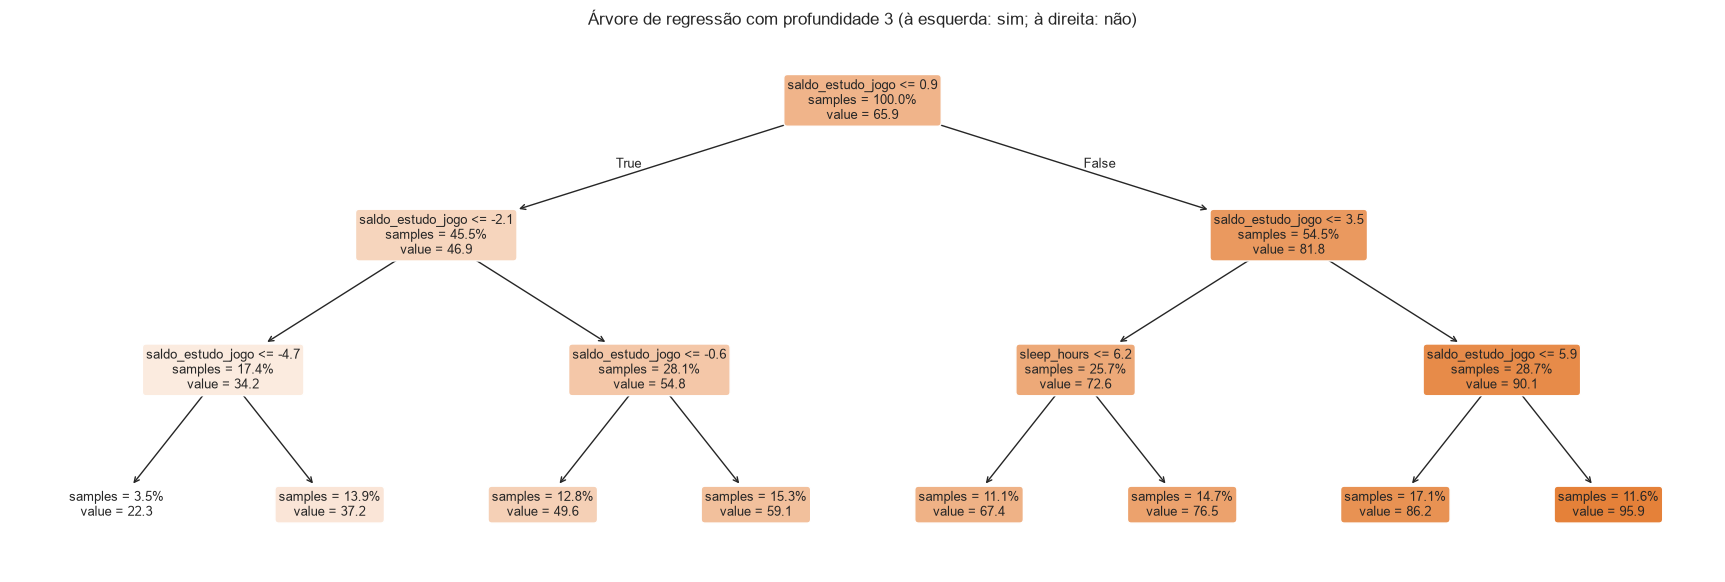

,MAE,RMSE
treino (ajuste),7.251,9.090
validação,7.176,9.022


In [27]:
arv3 = arvore(3).fit(X_aj, y_aj)
plt.figure(figsize=(22, 7))
plot_tree(arv3.named_steps['modelo'], feature_names=list(arv3.named_steps['preparo'].get_feature_names_out()), filled=True,
          rounded=True, proportion=True, impurity=False, fontsize=9, precision=1)
plt.title('Árvore de regressão com profundidade 3 (à esquerda: sim; à direita: não)')
plt.show()
pd.DataFrame({'treino (ajuste)': metricas(y_aj, arv3.predict(X_aj)), 'validação': metricas(y_val, arv3.predict(X_val))}).T

**Leitura.** A árvore escolhe sozinha as mesmas variáveis que a EDA apontou. Ela pergunta **três vezes seguidas pelo
`saldo_estudo_jogo`** (≤ 0,9 → ≤ −2,1 → ≤ −4,7) e só depois recorre a `sleep_hours`. As folhas vão de **22,3 pontos**
(quem joga quase 5 horas a mais do que estuda) a **95,9 pontos** (quem estuda quase 6 horas a mais do que joga):
74 pontos de diferença explicados por uma única conta.

Com profundidade 3 ela erra 7,25 pontos no ajuste e 7,18 na validação. Os dois números são **praticamente iguais**,
o que significa que ela ainda está simples demais (underfitting) e tem espaço para crescer.

## 6.4 Complexidade: underfitting e overfitting

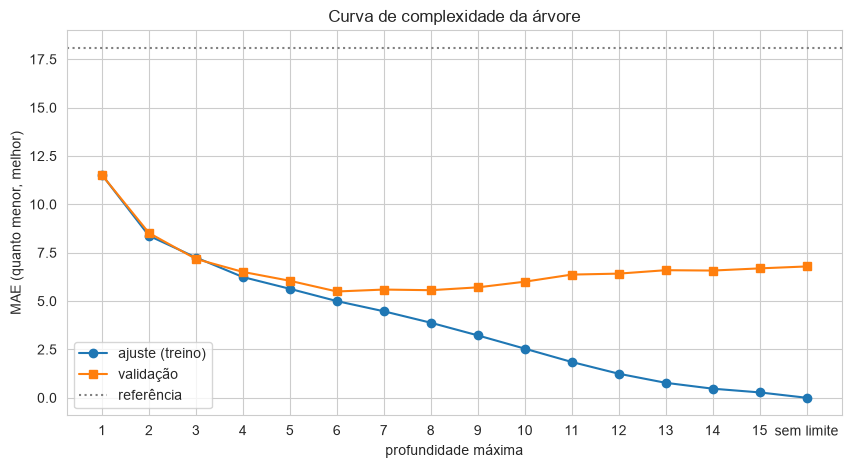

Profundidade com o menor MAE na validação: 6


,profundidade,folhas,MAE ajuste,MAE validação
0,1,2,11.522,11.510
2,3,8,7.251,7.176
5,6,64,4.998,5.494
9,10,835,2.539,6.000
15,sem limite,4175,0.000,6.789


In [28]:
profundidades = list(range(1, 16)) + [None]
curva = []
for p in profundidades:
    m = arvore(p, min_folha=1).fit(X_aj, y_aj)
    curva.append({'profundidade': 'sem limite' if p is None else p, 'folhas': m.named_steps['modelo'].get_n_leaves(),
                  'MAE ajuste': mean_absolute_error(y_aj, m.predict(X_aj)), 'MAE validação': mean_absolute_error(y_val, m.predict(X_val))})
curva = pd.DataFrame(curva)
eixo = curva['profundidade'].astype(str)
plt.plot(eixo, curva['MAE ajuste'], 'o-', label='ajuste (treino)')
plt.plot(eixo, curva['MAE validação'], 's-', label='validação')
plt.axhline(mae_ref, color='gray', ls=':', label='referência')
plt.xlabel('profundidade máxima')
plt.ylabel('MAE (quanto menor, melhor)')
plt.title('Curva de complexidade da árvore')
plt.legend()
plt.show()

PROFUNDIDADE = int(curva.iloc[:-1].loc[curva.iloc[:-1]['MAE validação'].idxmin(), 'profundidade'])
print(f'Profundidade com o menor MAE na validação: {PROFUNDIDADE}')
display(curva.iloc[sorted({0, 2, PROFUNDIDADE - 1, 9, len(curva) - 1})])

# Desafio 1: descomente a linha abaixo para usar, daqui em diante, uma árvore sem limite.
# PROFUNDIDADE, MIN_FOLHA = None, 1

**Leitura.** A curva reproduz exatamente o comportamento visto na aula 11, em três trechos:

- **Underfitting (profundidades 1 e 2):** as duas curvas são altas e colam uma na outra (11,52 e 11,51 na profundidade 1).
  A árvore é simples demais para a base.
- **Ponto de equilíbrio (profundidade 6):** o menor erro de validação, **5,49 pontos**, com 64 folhas. Daqui em diante
  as duas curvas se separam.
- **Overfitting (da profundidade 7 em diante):** o erro de ajuste continua caindo até **zero**, enquanto o de validação
  **sobe** — 5,59 na profundidade 7, 6,00 na 10 e **6,79** sem limite. Sem limite a árvore cria **4.175 folhas** para
  4.444 estudantes de ajuste: ela praticamente decora um estudante por folha. Decorar o treino não é aprender:
  o que cresce é a memória, não a capacidade de generalizar.

## 6.5 Escolha do modelo na validação

In [29]:
candidatos_val[f'árvore (profundidade {PROFUNDIDADE or "sem limite"})'] = arvore(PROFUNDIDADE).fit(X_aj, y_aj)
comparacao = pd.DataFrame({k: metricas(y_val, m.predict(X_val), mae_ref) for k, m in candidatos_val.items()}).T.sort_values('MAE')
MODELO_ESCOLHIDO = comparacao.index[0]
display(comparacao)
print('Modelo escolhido pelo MAE na validação:', MODELO_ESCOLHIDO)

,MAE,RMSE,redução do MAE
regressão linear,5.107,6.342,0.718
árvore (profundidade 6),5.478,6.971,0.697
regra de uma pergunta,11.510,14.011,0.364
referência (média),18.093,21.826,0.000


Modelo escolhido pelo MAE na validação: regressão linear


**Leitura.** A **regressão linear vence** na validação, com MAE de 5,11 contra 5,48 da árvore de profundidade 6 —
uma diferença de 0,37 ponto, pequena mas consistente, e que se repete no RMSE (6,34 contra 6,97). O resultado faz
sentido: a EDA mostrou relações lineares, sem patamares nem curvas, e é exatamente nesse cenário que a reta vence a
árvore, que só consegue aproximar uma reta por degraus.

Além de errar menos, a linear é mais simples de explicar e dá um número por variável. **Modelo escolhido:
regressão linear.** Essa decisão é tomada **sem olhar o teste** — ele continua guardado.

## 6.6 Verificação de redundância: a regressão precisa das quatro medidas de jogo?

In [30]:
REDUNDANTES = ['reaction_time_ms', 'addiction_score', 'device_usage']   # as três que repetem gaming_hours

def criar_preparo_sem(colunas):
    num = [c for c in NUM if c not in colunas]
    return ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), num),
        ('categoricas', Pipeline([('ausente', SimpleImputer(strategy='constant', fill_value='ausente')),
                                  ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT)],
        verbose_feature_names_out=False)

linear_sem = Pipeline([('preparo', criar_preparo_sem(REDUNDANTES)), ('modelo', LinearRegression())]).fit(X_aj, y_aj)
arvore_sem = Pipeline([('preparo', criar_preparo_sem(REDUNDANTES)),
                       ('modelo', DecisionTreeRegressor(max_depth=PROFUNDIDADE, min_samples_leaf=MIN_FOLHA,
                                                        random_state=SEED))]).fit(X_aj, y_aj)
display(pd.DataFrame({
    'regressão linear (todas as features)': metricas(y_val, linear.predict(X_val), mae_ref),
    'regressão linear (sem o bloco redundante)': metricas(y_val, linear_sem.predict(X_val), mae_ref),
    f'árvore {PROFUNDIDADE} (todas as features)': metricas(y_val, candidatos_val[f'árvore (profundidade {PROFUNDIDADE})'].predict(X_val), mae_ref),
    f'árvore {PROFUNDIDADE} (sem o bloco redundante)': metricas(y_val, arvore_sem.predict(X_val), mae_ref),
}).T)

# Os coeficientes do bloco redundante são estáveis quando ele sai do modelo?
def coefs(modelo):
    return pd.Series(modelo.named_steps['modelo'].coef_, index=modelo.named_steps['preparo'].get_feature_names_out())

comp_coef = pd.DataFrame({'com o bloco redundante': coefs(linear), 'sem o bloco redundante': coefs(linear_sem)})
comp_coef['diferença'] = comp_coef.iloc[:, 1] - comp_coef.iloc[:, 0]
display(comp_coef.reindex(['saldo_estudo_jogo', 'study_hours', 'gaming_hours', 'sleep_hours', 'attendance',
                           'reaction_time_ms', 'addiction_score', 'device_usage']).round(2))

,MAE,RMSE,redução do MAE
regressão linear (todas as features),5.107,6.342,0.718
regressão linear (sem o bloco redundante),5.109,6.344,0.718
árvore 6 (todas as features),5.478,6.971,0.697
árvore 6 (sem o bloco redundante),5.479,6.972,0.697


,com o bloco redundante,sem o bloco redundante,diferença
saldo_estudo_jogo,3.880,3.860,-0.020
study_hours,1.920,1.940,0.020
gaming_hours,-1.950,-1.920,0.040
sleep_hours,3.540,3.540,0.000
attendance,0.270,0.270,-0.000
reaction_time_ms,-0.010,NaN,NaN
addiction_score,0.020,NaN,NaN
device_usage,-0.060,NaN,NaN


**Leitura.** Tirar as três variáveis redundantes **não piora nenhum modelo**: a regressão linear mantém MAE de 5,11
na validação (diferença na terceira casa decimal) e a árvore de profundidade 6 também fica igual. As três colunas
não carregavam informação própria — exatamente o que o VIF de 3.7 e as correlações parciais da AV1 indicavam.

A tabela de coeficientes mostra por que isso importa para a interpretação. Com o bloco no modelo, `reaction_time_ms`,
`addiction_score` e `device_usage` recebem coeficientes próximos de zero (de −0,06 a +0,02), mas **não nulos**, e esses
valores só existem para compensar umas às outras. Já os coeficientes das variáveis que realmente importam
(`saldo_estudo_jogo`, `sleep_hours`, `study_hours`) praticamente não se alteram quando o bloco sai.

**Decisão:** o modelo final mantém as três colunas, porque o objetivo é prever e elas não atrapalham o desempenho —
mas **os coeficientes delas não são interpretados** em 8.1, e a conclusão do projeto trata as quatro medidas de jogo
como **um único fator**, não como quatro. Se o objetivo fosse explicar em vez de prever, a escolha correta seria
remover as três.

# 7. Avaliação final no teste

,MAE,RMSE,redução do MAE
referência (média),18.771,22.613,0.000
regra de uma pergunta,11.966,14.387,0.363
regressão linear,5.141,6.464,0.726
árvore (profundidade 6),5.728,7.228,0.695


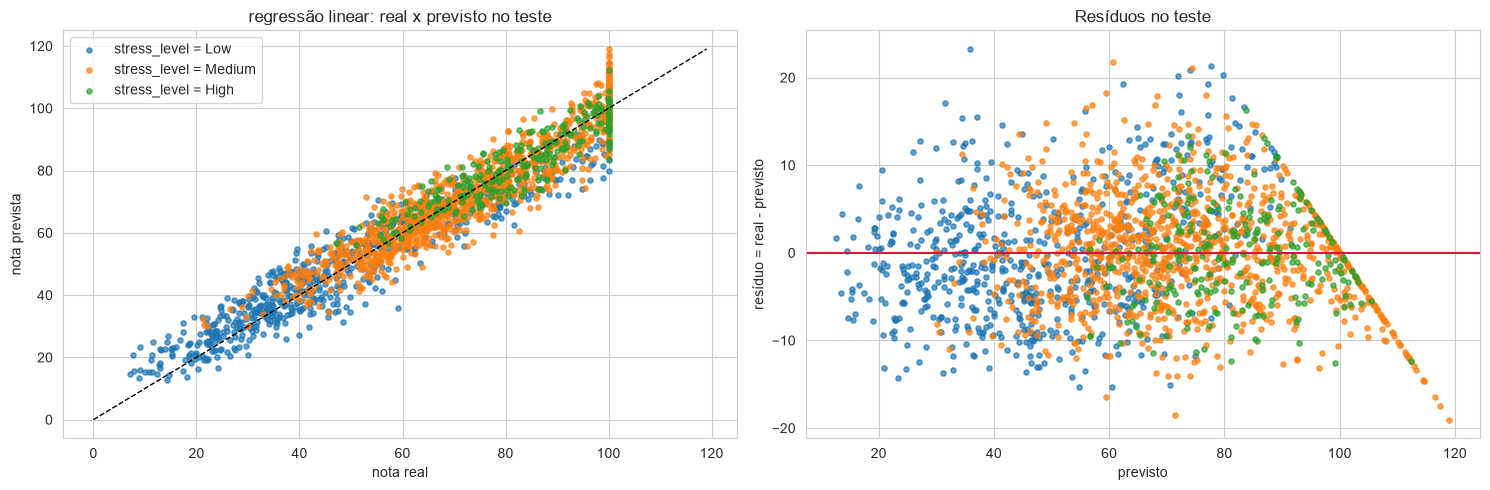

Resíduo médio: -0.07 | desvio padrão do resíduo: 6.47


In [31]:
finais = {'referência (média)': pipe(DummyRegressor(strategy='mean')), 'regra de uma pergunta': arvore(1),
          'regressão linear': pipe(LinearRegression()), f'árvore (profundidade {PROFUNDIDADE or "sem limite"})': arvore(PROFUNDIDADE)}
finais = {k: m.fit(X_treino, y_treino) for k, m in finais.items()}
mae_ref_teste = mean_absolute_error(y_teste, finais['referência (média)'].predict(X_teste))
display(pd.DataFrame({k: metricas(y_teste, m.predict(X_teste), mae_ref_teste) for k, m in finais.items()}).T)

final = finais[MODELO_ESCOLHIDO]
prev_teste = final.predict(X_teste)
residuo = y_teste - prev_teste
grupo = amplitude.index[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for valor in X_teste[grupo].unique():
    sel = (X_teste[grupo] == valor).values
    axes[0].scatter(y_teste[sel], prev_teste[sel], s=14, alpha=0.7, label=f'{grupo} = {valor}')
    axes[1].scatter(prev_teste[sel], residuo[sel], s=14, alpha=0.7, label=f'{grupo} = {valor}')
lim = [0, max(y_teste.max(), prev_teste.max())]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set(xlabel='nota real', ylabel='nota prevista', title=f'{MODELO_ESCOLHIDO}: real x previsto no teste')
axes[1].axhline(0, color='crimson')
axes[1].set(xlabel='previsto', ylabel='resíduo = real - previsto', title='Resíduos no teste')
axes[0].legend()
plt.tight_layout()
plt.show()
print(f'Resíduo médio: {residuo.mean():,.2f} | desvio padrão do resíduo: {residuo.std():,.2f}')

**Leitura.** No teste — 1.976 estudantes que nenhum modelo tinha visto:

| Modelo | MAE (pontos) | RMSE | Redução sobre a referência |
|---|---|---|---|
| referência (média) | 18,77 | 22,61 | — |
| regra de uma pergunta | 11,97 | 14,39 | 36% |
| **regressão linear** | **5,14** | **6,46** | **73%** |
| árvore (profundidade 6) | 5,73 | 7,23 | 69% |

A regressão linear erra, em média, **5,1 pontos** de nota. A ordem dos modelos é a mesma da validação e os valores
quase não mudam (5,11 na validação contra 5,14 no teste): **não houve overfitting na escolha do modelo**.

O gráfico de real × previsto mostra os pontos distribuídos ao longo da diagonal em toda a escala, e o de resíduos
mostra uma faixa horizontal em torno de zero (resíduo médio −0,07, desvio 6,47), sem funil nem curva. As duas únicas
distorções visíveis estão nos extremos: acima de 95 o modelo tende a **subestimar** e abaixo de 10 a **superestimar**,
efeito esperado porque a nota é limitada a [0, 100] e a reta não conhece esse limite.

# 8. Análise de erros e interpretação

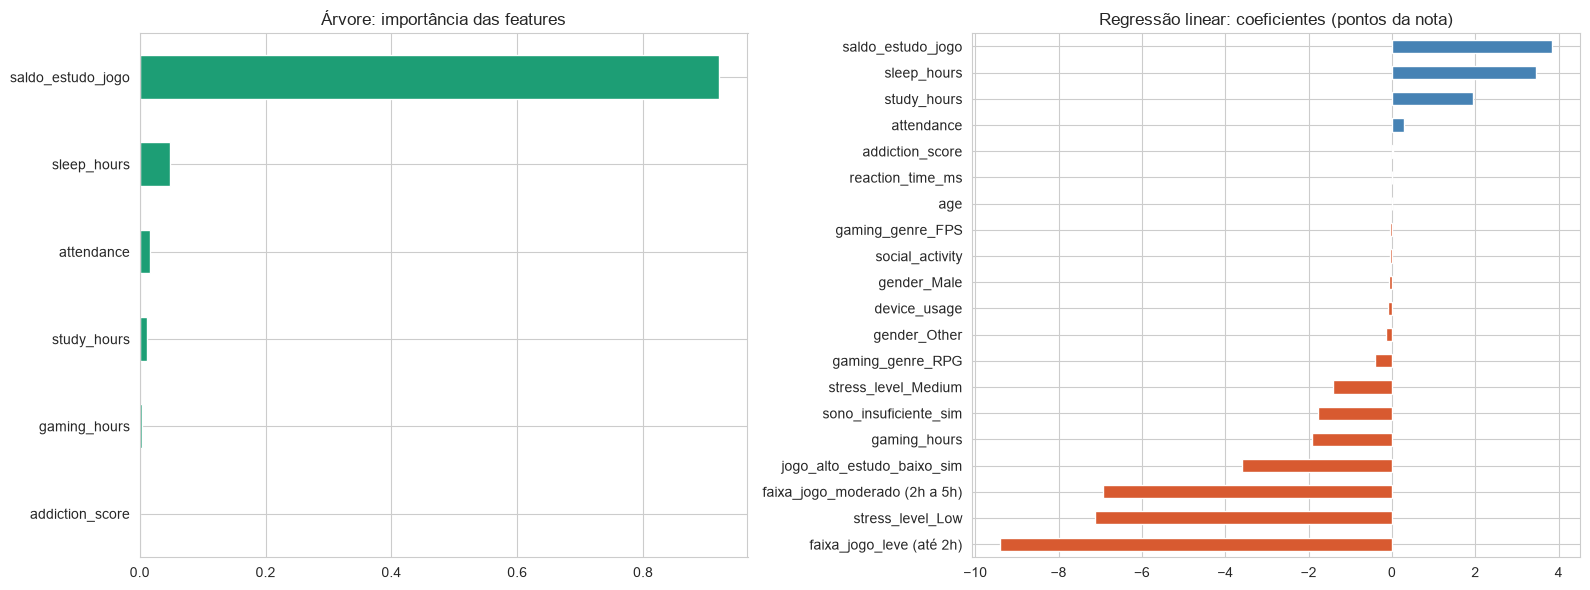

,importância na árvore
saldo_estudo_jogo,0.920
sleep_hours,0.049
attendance,0.017
study_hours,0.011
gaming_hours,0.003


In [32]:
arv_final = finais[f'árvore (profundidade {PROFUNDIDADE or "sem limite"})']
imp = pd.Series(arv_final.named_steps['modelo'].feature_importances_, index=arv_final.named_steps['preparo'].get_feature_names_out())
coef = pd.Series(finais['regressão linear'].named_steps['modelo'].coef_, index=finais['regressão linear'].named_steps['preparo'].get_feature_names_out())
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
imp[imp > 0].sort_values().plot.barh(ax=axes[0], color='#1D9E75', title='Árvore: importância das features')
coef.sort_values().plot.barh(ax=axes[1], color=['#D85A30' if v < 0 else 'steelblue' for v in coef.sort_values()],
                             title='Regressão linear: coeficientes (pontos da nota)')
plt.tight_layout()
plt.show()
display(imp[imp > 0.001].sort_values(ascending=False).round(3).to_frame('importância na árvore'))

**Leitura.** Os dois modelos apontam para a mesma variável, criada na seção 4.1 a partir da EDA:

- **Árvore:** `saldo_estudo_jogo` concentra **92%** de toda a importância. Sobram 4,9% para `sleep_hours`,
  1,7% para `attendance` e 1,1% para `study_hours`. Todas as demais ficam em zero — inclusive `addiction_score`,
  `device_usage` e `reaction_time_ms`, que tinham correlação forte com a nota mas **não acrescentam nada** depois
  que o saldo entre estudo e jogo já está no modelo. É a confirmação prática da redundância diagnosticada em 3.7.
- **Regressão linear:** o maior coeficiente positivo é `saldo_estudo_jogo` (+3,85 pontos por hora de saldo), seguido
  por `sleep_hours` (+3,46 por hora) e `study_hours` (+1,93). Os negativos são `faixa_jogo` e `stress_level_Low`,
  que, como explicado em 6.2, estão corrigindo o que o saldo já captou e não devem ser lidos isoladamente.

**A mensagem prática do projeto está nessa variável.** O que prevê a nota não é "quantas horas o estudante joga",
isolado, mas **quanto ele estuda a mais (ou a menos) do que joga**. Isso reforça a conclusão da AV1: a recomendação
útil é garantir horas de estudo, não simplesmente proibir o jogo.

## 8.2 Onde o modelo erra

In [33]:
erros = X_teste.assign(real=y_teste.values, previsto=prev_teste.round(1), erro_absoluto=np.abs(residuo).round(1))
erros['erro %'] = (100 * erros['erro_absoluto'] / erros['real'].replace(0, np.nan)).round(1)
for c in list(amplitude.index[:2]) + ['faixa_jogo']:
    display(erros.groupby(c, observed=True).agg(n=('real', 'size'), nota_media=('real', 'mean'), MAE=('erro_absoluto', 'mean'),
                                                erro_pct_mediano=('erro %', 'median')).round(2))
print('Os 5 maiores erros no teste:')
erros.sort_values('erro_absoluto', ascending=False).head(5)[
    ['gaming_hours', 'study_hours', 'sleep_hours', 'attendance', 'stress_level', 'faixa_jogo',
     'saldo_estudo_jogo', 'real', 'previsto', 'erro_absoluto']]

,n,nota_media,MAE,erro_pct_mediano
stress_level,,,,
High,249,81.190,4.550,5.100
Low,677,48.230,5.800,11.000
Medium,1050,72.830,4.850,5.600


,n,nota_media,MAE,erro_pct_mediano
gender,,,,
Female,945,65.590,5.170,6.900
Male,971,65.240,5.130,6.900
Other,60,66.790,4.790,6.050


,n,nota_media,MAE,erro_pct_mediano
faixa_jogo,,,,
excessivo (+5h),772,51.070,5.650,10.200
leve (até 2h),477,81.900,5.370,5.500
moderado (2h a 5h),727,69.950,4.450,5.400


Os 5 maiores erros no teste:


,gaming_hours,study_hours,sleep_hours,attendance,stress_level,faixa_jogo,saldo_estudo_jogo,real,previsto,erro_absoluto
1515,5.870,2.700,4.850,97.940,Low,excessivo (+5h),-3.170,59.054,35.800,23.300
6803,3.510,4.090,6.710,72.310,Medium,moderado (2h a 5h),0.580,82.547,60.700,21.800
6894,5.160,8.430,6.380,76.870,Low,excessivo (+5h),3.270,98.992,77.600,21.400
7708,1.280,2.940,7.570,98.320,Medium,leve (até 2h),1.660,95.491,74.400,21.100
6239,5.450,7.810,6.410,80.230,Low,excessivo (+5h),2.360,94.774,73.900,20.800


**Leitura.** O erro é **homogêneo**: não há nenhum subgrupo em que o modelo falhe de forma sistemática.

- Por `stress_level`: MAE de 4,55 (High), 4,85 (Medium) e 5,80 (Low). O grupo de estresse baixo é o mais difícil,
  mas a diferença é de pouco mais de um ponto. Em erro percentual a diferença parece maior (11,0% contra 5,1%),
  e isso é só aritmética: esse grupo tem nota média 48,2, então o mesmo erro absoluto pesa mais na porcentagem.
- Por `faixa_jogo`: 4,45 (moderado), 5,37 (leve) e 5,65 (excessivo). Os extremos são um pouco mais difíceis que o meio.
- Por `gender`: 4,79 a 5,17, praticamente sem diferença — **o modelo não erra mais para um gênero do que para outro**,
  o que é relevante caso ele fosse usado para direcionar apoio a estudantes.

O maior erro de todo o teste é de **23,3 pontos**: um registro com 5,9h de jogo, 2,7h de estudo e 4,9h de sono —
perfil de nota baixa, para o qual o modelo previu 35,8 — mas cuja nota real foi 59,1. Os cinco maiores erros têm o
mesmo padrão: estudantes
cujas notas não se explicam pelo que a base mede. Nenhum deles é erro de dado; é o **limite de informação da base** —
ela não tem nada sobre dificuldade das disciplinas, condição socioeconômica, trabalho ou saúde.

# 9. Conclusões

1. **A base está limpa, mas é simulada.** A auditoria não encontrou ausentes, duplicatas nem inconsistência de
   categorias. Encontrou 339 valores impossíveis (4,2% da base), tratados com as mesmas regras da AV1. As
   distribuições uniformes e a ausência total de outliers confirmam que os dados são sintéticos.
2. **Uma variável criada resolve quase todo o problema.** `saldo_estudo_jogo` (`study_hours − gaming_hours`) responde
   por 92% da importância da árvore e é a base da melhor pergunta única (MAE 11,97 no teste sozinha).
3. **Quatro variáveis medem a mesma coisa.** `gaming_hours`, `device_usage`, `addiction_score` e `reaction_time_ms`
   têm correlação entre si de 0,79 a 0,94. Depois que o tempo de jogo entra no modelo, as outras três não acrescentam
   nada. Isso resolve o resultado contraintuitivo do tempo de reação apontado na AV1.
4. **O estresse é marcador, não causa.** A associação positiva de `stress_level` com a nota (31,2 pontos de amplitude)
   se explica porque estresse alto se concentra entre quem estuda muitas horas. Era a principal dúvida deixada pela AV1.
5. **Não existe um "ponto de virada" nas horas de jogo.** A nota cai de forma contínua: 82,1 (até 2h), 69,5 (2h a 5h),
   52,4 (mais de 5h). O grupo realmente crítico é definido pela combinação jogo alto **e** estudo baixo:
   791 estudantes com nota média de 33,5.
6. **A regressão linear foi escolhida e generalizou.** MAE de 5,11 na validação e **5,14 no teste** (73% abaixo da
   referência de 18,77). Validação e teste quase iguais: não houve overfitting na escolha.
7. **Não há vazamento.** Nenhuma feature prevê a nota sozinha abaixo do limite de 20% do erro da referência; a coluna
   fictícia `nota_prova_final` mostra como um vazamento se denunciaria (9%).
8. **Os erros são homogêneos.** MAE entre 4,5 e 5,8 pontos em todos os subgrupos, inclusive entre gêneros.

## Decisão: **Investigar**

O modelo passa em todos os critérios técnicos de "Aplicar": o alvo existe, as features são conhecidas antes da prova,
não há vazamento, o modelo supera a referência com folga (73%) e validação e teste ficam a 0,03 ponto um do outro.

O que impede a aplicação não é o modelo, é a **origem dos dados**. A base é declaradamente simulada, e três evidências
deste notebook confirmam: distribuições uniformes com cortes exatos, zero outliers pela regra do IQR e um bloco de
quatro variáveis com correlação de até 0,94 entre si — padrões que não aparecem em dados reais de uma instituição.
Um MAE de 5,1 pontos mede a qualidade do gerador dos dados, não a dificuldade real de prever o desempenho de um
estudante.

**O que falta para mudar a decisão para "Aplicar":** repetir exatamente este notebook sobre dados reais de uma
instituição, com horas de estudo e de jogo coletadas antes do fechamento das notas. Se o MAE sobre dados reais
continuar bem abaixo da referência, o modelo pode apoiar a decisão concreta a que este projeto se dirige —
**identificar, no início do semestre, estudantes que precisam de apoio no acompanhamento acadêmico**.
Essa é justamente a decisão trabalhada no notebook de classificação do grupo, onde o alvo é o risco de ficar abaixo
da nota de corte.

# 10. Desafios

Respondidos com os números da **base de exemplo da oficina** (`insurance.csv`, custo de plano de saúde), como pede o
enunciado. Cada alteração foi feita, executada e depois desfeita.

### 1. Complexidade

Na curva de 6.4 da base de exemplo, a árvore **sem limite** tem **751 folhas**, MAE de ajuste **0,00** e MAE de
validação **3.096,63** — contra 1.856,58 e 2.670,59 da árvore de profundidade 7.

Descomentando `PROFUNDIDADE, MIN_FOLHA = None, 1` e rodando tudo:

| Modelo | MAE validação | MAE teste |
|---|---|---|
| árvore profundidade 7 (original) | 2.670,59 | 2.595,58 |
| árvore sem limite | 3.096,63 | **3.143,70** |
| regressão linear | 2.622,34 | 2.426,99 |

A escolha de 6.5 **não muda**: a regressão linear continua com o menor MAE na validação (2.622,34 contra 3.096,63 da
árvore sem limite), então o modelo final é o mesmo. O que muda é a árvore: no teste ela passa a errar 548 USD a mais.

Com MAE zero no ajuste, a árvore sem limite **decorou** cada cliente do conjunto de ajuste: **751 folhas para 751 clientes**,
uma folha por cliente. Erro de ajuste zero e erro de validação alto é a definição de **overfitting** — o modelo não aprendeu o
padrão, guardou os exemplos. **Generalização** é o contrário: ir bem em dados nunca vistos, e é por isso que a
escolha é feita pelo erro de validação, nunca pelo de ajuste.

### 2. Métrica

Trocando `sort_values('MAE')` por `sort_values('RMSE')` em 6.5:

| Modelo | MAE validação | RMSE validação | RMSE / MAE |
|---|---|---|---|
| regressão linear | 2.622,34 | 4.832,20 | 1,84 |
| árvore (profundidade 7) | 2.632,87 | 4.959,50 | 1,88 |
| regra de uma pergunta | 5.813,02 | 7.498,73 | 1,29 |
| referência (média) | 9.139,09 | 12.143,34 | 1,33 |

**O modelo escolhido não muda:** a regressão linear tem tanto o menor MAE quanto o menor RMSE. Mas as duas métricas
ficam quase empatadas entre linear e árvore no MAE (0,4% de diferença) e um pouco mais separadas no RMSE (2,6%).

O RMSE ser quase o dobro do MAE nos dois melhores modelos mostra que o erro **não é uniforme**: existe um grupo
pequeno de clientes com erro muito grande puxando o RMSE para cima (o RMSE eleva cada erro ao quadrado antes de somar,
então dá peso maior aos erros grandes). São os casos da seção 8.2 — não fumantes com custo muito acima do que as
variáveis da base explicam. Já a referência e a regra de uma pergunta têm razão RMSE/MAE perto de 1,3: elas erram
muito, mas erram de forma parecida em todos os clientes.

Em termos de escolha: **usar RMSE quando um erro grande custa desproporcionalmente mais** do que vários pequenos
(prever 20 mil a menos em um caso é pior do que errar 2 mil em dez casos); usar **MAE quando o custo é proporcional**
ao tamanho do erro. Para precificar plano de saúde, o MAE é a métrica mais direta: ele está em dólares de erro médio.

### 3. Vazamento

Na base de exemplo, `valor_reembolsado` sozinha erra **827 USD** — apenas **9,2% do erro da referência** (9.019 USD) —
enquanto a melhor feature real, `smoker`, erra 5.776 USD (64%). O motivo é que a coluna foi construída como 80% do
próprio alvo mais ruído: ela **é** o alvo disfarçado.

O problema não é estatístico, é de **cronologia**. O valor reembolsado só existe **depois** que o cliente usou o plano;
a previsão precisa ser feita **antes**, no momento de precificar. Um modelo treinado com ela teria MAE excelente no
notebook e seria inútil na prática — na hora de usar, a coluna estaria vazia. A regra é: toda feature precisa estar
disponível **no instante em que a decisão é tomada**.

**No projeto do grupo**, colunas com o mesmo problema seriam: a **nota de um bimestre posterior**, a **situação final**
(aprovado/reprovado), a **frequência fechada no fim do semestre** ou um encaminhamento para reforço feito depois do
resultado. Todas são consequência da nota, não antecedentes dela. Foi por isso que a coluna fictícia `nota_prova_final`
entrou na seção 5.3 deste notebook: ela erra 1,6 ponto sozinha (9% da referência) e é marcada como possível vazamento,
exatamente como `valor_reembolsado`.

### 4. Features

Acrescentando `'smoker'` a `COLUNAS_FORA` e retirando a linha de `fumante_obeso` de `criar_atributos`:

| | MAE teste original | MAE teste sem `smoker` | Piora |
|---|---|---|---|
| regressão linear | 2.426,99 | **9.208,92** | **+6.781,93 (3,8× pior)** |
| referência (média) | 9.540,31 | 9.540,31 | — |

O MAE da regressão linear passa de 2.427 para 9.209 USD, ou seja, o modelo fica **praticamente empatado com a
referência** (9.540): sem `smoker`, prever o custo de um cliente passa a ser quase o mesmo que chutar a média.
A profundidade escolhida pela validação também desaba de 7 para **1**, porque não há mais nada que valha a pena
perguntar duas vezes.

Isso diz que **`smoker` não é uma variável importante, é praticamente a única variável**. Nenhuma das demais
(`age`, `bmi`, `children`, `sex`, `region`) tem substituto à altura, e a árvore não encontra nenhuma combinação que
recupere o sinal perdido. Coerente com a EDA, que mostrava fumantes custando 31 mil contra 8 mil dos não fumantes.

### 5. Referência

Sim, a regra de uma pergunta já supera a referência, e com folga: no teste, MAE de **5.351,18** contra **9.540,31**
da referência — **44% menos erro, com uma única pergunta** ("o cliente é fumante e obeso?").

O modelo escolhido acrescenta a isso: a regressão linear erra **2.426,99**, ou seja, **2.924,19 USD a menos** que a
regra de uma pergunta (55% de redução adicional).

**Vale a complexidade?** Sim, neste caso. A regra de uma pergunta divide a base em apenas dois grupos e prevê o
mesmo valor para todos dentro de cada grupo — um não fumante de 18 anos e um de 64 recebem a mesma previsão. A
regressão linear custa pouco (é um modelo explicável, com um coeficiente por variável, que roda instantaneamente) e
reduz o erro pela metade. O quadro seria diferente se o ganho fosse de 5% ou se o modelo escolhido fosse uma caixa-preta:
aí a regra simples, por ser auditável, poderia valer mais.

# 11. Entrega: o que foi adaptado

Este notebook é a cópia do `oficina_ML_regressao.ipynb` adaptada à base do projeto. O que mudou em relação ao original:

| Seção | Alteração |
|---|---|
| 0. Parâmetros | `ALVO = 'grades'` (nota de 0 a 100), `COLUNAS_FORA = ['student_id']`, carregamento do CSV local do projeto com os caminhos do repositório e fallback para o Kaggle |
| 1.2 Faixas de validade | Regras do domínio da base do projeto: nota em [0, 100], frequência em [0, 100], escore de dependência ≥ 0, idade plausível e soma de horas ≤ 24 |
| 1.3 `limpar` | As três regras definidas na AV1: limitar `grades` a 100, limitar `addiction_score` a 0 e remover as linhas com mais de 24h somadas |
| 3.2 e 3.5 | Grades de gráficos reorganizadas para as nove numéricas da base (a de exemplo tinha três) e amostragem de 2.000 pontos nos gráficos de dispersão |
| 3.4 | Tratamento do caso "nenhum outlier encontrado", que não ocorre na base de exemplo |
| 3.7 | Acrescentada a tabela cruzada de `stress_level` por faixa de `study_hours`, para investigar o achado contraintuitivo da AV1 |
| 4.1 `criar_atributos` | Quatro variáveis novas: `faixa_jogo`, `saldo_estudo_jogo`, `jogo_alto_estudo_baixo` e `sono_insuficiente` |
| 5.3 | A coluna fictícia de vazamento passou de `valor_reembolsado` para `nota_prova_final` |
| 5.4 | Teste de robustez com `study_hours` ausente e a categoria inexistente `stress_level = 'Extremo'` |
| 8.2 | Análise de erro também por `faixa_jogo`, e proteção contra divisão por zero no erro percentual (há um estudante com nota 0) |
| Textos | Todas as células **Leitura**, a síntese 3.8 e as conclusões da seção 9 foram reescritas com os números da base do projeto |
| 10 | Desafios respondidos com os números da base de exemplo, como pede o enunciado |

**Arquivos do projeto:**

- `Analise_GrupoGamingvsAcademicPerformance.ipynb` — preparação e EDA (AV1)
- `oficina_ML_Regressao_GrupoGamingvsAcademicPerformance.ipynb` — este notebook
- `oficina_ML_Classificacao_GrupoGamingvsAcademicPerformance.ipynb` — risco de baixo desempenho
- `dados/Base_Original_GrupoGamingvsAcademicPerformance.csv` — base usada aqui